# MOLECULE STRUCTURE CLUSTERING (V2)

Uses the fingerprint MAP4.
Uses the notation 03/2022 with new sdfs.

In [36]:
def compute_distance_matrix(df, path = None, metric='jaccard'):
    
    '''
    Computes and optionally saves in the provided path
    the similarity/distance matrix of a given binary dataFrame.
    The metric by default is jaccard.
    '''
    
    matrix = pairwise_distances(np.array(df), metric=metric)
    
    if path != None:
        with open(path, 'wb') as fp:
            pickle.dump(distances, fp)
    
    return matrix

In [37]:
def structure_clustering(threshold, linkage, metric='jaccard', distance_matrix = None, df=None):
    
    '''
    Implements aglomerative hierarchical clustering.
    
    - df: the training dataset
    - threshold: The linkage distance threshold above which, clusters will not be merged.
    - linkage: 'simple', 'average', 'complete' or 'ward'. If ward is employed, the metric
    must be changed to 'euclidean'.
    - distance_matrix: a precomputed distance matrix is prefered to decrease times of computation.
    
    Returns the sklearn model
    '''
    if df is None and distance_matrix is None:
        print('Nor distance matrix either dataset was passed as argument')
        return False
    
    
    if distance_matrix is None:
        distance_matrix = compute_distance_matrix(df)
    
    if linkage == 'ward' and metric != 'euclidean':
        print('The linkage ward can be only employed with euclidean similarity')
    elif linkage == 'ward' and metric == 'euclidean':
        model = AgglomerativeClustering(n_clusters = None, linkage = linkage, distance_threshold = threshold, affinity = 'euclidean').fit(df)
    else:       
        model = AgglomerativeClustering(n_clusters = None,linkage = linkage, distance_threshold = threshold, affinity = 'precomputed').fit(distance_matrix)
    
    return model

In [38]:
def save(trained_model, path):
    '''
    Saves the hierarchical clustering model.
    
    - trained_model: is an output of structure_clustering function
    - path: string containing the directory to be saved. The filename
    must be in format .joblib.
    '''
    
    joblib.dump(trained_model, path)

In [39]:
def get_clusters(df_smiles, trained_model):
    
    '''
    From a trained model and the dataset it obstains a 
    dictionary where the keys are the cluster number
    and the values are the lists of the ID belonging to
    that cluster
    '''
    
    clusters = {}
    n_clusters = get_nclusters(trained_model)
    labels = trained_model.labels_
    df_aux = df_smiles.copy()
    df_aux['label'] = labels
    for cluster in list(range(0, n_clusters)):
        
        clusters[cluster] = list(df_aux[df_aux['label'] == cluster].index)
        
    return clusters

In [40]:
def get_clusters_v2(df, trained_model):
    
    '''
    From a trained model and the dataset it obstains a 
    dictionary where the keys are the cluster number
    and the values are the lists of the indexes belonging to
    that cluster
    '''
    
    clusters = {}
    n_clusters = get_nclusters(trained_model)
    labels = trained_model.labels_
    df_new = df.copy()
    df_new = df_new.reset_index()
    df_new['label'] = labels
    for cluster in list(range(0, n_clusters)):
        
        clusters[cluster] = list(df_new[df_new['label'] == cluster].index)
        
    return clusters

In [41]:
def get_substructures_similarities_map4(df_smiles, distances_sub_lst_complete, leaves, children_new, distance_matrix, distances, linkage='complete'):
    
        '''
        Obtains a list of list in which echa least correspond to a dendrogram_distance
        elements and contains the substructures of all the clusters obtained with this distance.
        '''
        sim_lst_lst_lst = []
        n_clusters_lst = []
        n_samples = len(distances) + 1
        j=0
        for distance in distances:
            print('PROGRESS: ' + str(j/len(distances) * 100))
            trained_model = structure_clustering(distance, linkage, distance_matrix = distance_matrix)
            clusters = get_clusters(df_smiles, trained_model)
            n_clusters = get_nclusters(trained_model)
            
            n_clusters_lst.append(n_clusters)
            
            sim_lst_lst = []
        
            for key, value in clusters.items():
                flag = True
                
                sim_lst = []
                if len(value) == 1:
                    sim_lst.append(0.)
                    flag=False
                else:
                    for key_2, value_2 in leaves.items():
                        if set(value) == set(value_2):
                            flag = False
                            key_objective = key_2
                            i = np.argwhere(children_new[:, 2] == key_objective)[0][0]
                            sim_lst = distances_sub_lst_complete[int(key_objective) - n_samples]
                            #arr = np.array([df_MCS.loc[int(key_objective)].values, df.iloc[index].values])
                            #sim_lst.append(pairwise_distances(arr, metric = metric)[0, 1])
                            
                            
                if flag:
                    print('ERROR: Cluster ' + str(key) + ' not identified')
                sim_lst_lst.append(sim_lst)
                
            sim_lst_lst_lst.append(sim_lst_lst)

            j+=1
                     
        return sim_lst_lst_lst, n_clusters_lst

In [42]:
def get_cluster_size(trained_model):
    
    '''
    Returns the percentage of the total number of
    examples that is contained in each cluster
    '''
    
    labels = trained_model.labels_
    total = len(labels)
    clusters, count = np.unique(labels, return_counts = True)
    
    size = {}
    for i, cluster in enumerate(clusters):
        size[cluster] = count[i]/total*100
        
    return size

In [43]:
def get_nclusters(trained_model):
    
    '''
    Returns the number of clusters
    '''
    
    return trained_model.n_clusters_

In [44]:
def draw_cluster(df_smiles, trained_model, cluster, clusters):
    
    '''
    Returns the fraction of the sdf dataset that is contained 
    in the querying cluster
    '''
    
    lst = clusters[cluster]
    cluster_df = pd.DataFrame()
    df_aux = df_smiles.copy()
    for element in lst:
        cluster_df = cluster_df.append(df_aux.iloc[element])
    
    return cluster_df

In [45]:
def leaves_search(third, children_new, leaves_lst, n_samples):
    
    first = children_new[np.argwhere(children_new[:, 2] == third)[0][0], 0]
    second = children_new[np.argwhere(children_new[:, 2] == third)[0][0], 1]
    if first >= n_samples:
        leaves_search(first, children_new, leaves_lst, n_samples)
    else:
        leaves_lst.append(int(first))
        
    if second >= n_samples:
        leaves_search(second, children_new, leaves_lst, n_samples)
    else:
        leaves_lst.append(int(second))
        
    return leaves_lst

In [46]:
def get_leaves(children):
    
    n_samples = children.shape[0] + 1
    children_new = np.zeros((children.shape[0],children.shape[1]+1))
    children_new[:,:-1] = children
    
    for index, row in enumerate(children_new):
        row[2] =  n_samples + index
        children_new[index] = row
    
    leaves = {}
    third = children_new[0]
    first = children_new[0][0]
    second = children_new[0][1]
       
    for index, row in enumerate(children_new):
        leaves[int(row[2])] = []
        third = int(row[2])
        
        leaves_lst = []
        leaves_lst = leaves_search(third, children_new, leaves_lst, n_samples)
        leaves[int(row[2])] = leaves_lst
        
                
    return leaves, children_new

In [47]:
def get_substructures(df, threshold, distance_matrix, dendrogram_distances, linkage='complete'):
    model = structure_clustering(df, threshold, linkage, distance_matrix = distance_matrix)
    n_clusters = get_nclusters(model)
    for i, distance in enumerate(dendrogram_distances):
        if threshold <= distance:
            index = i
            break
    
    return n_clusters, index
        

In [48]:
def get_distances(trained_model):
    '''
    Returns the distances at which a change in the number of clusters
    is found
    '''
    
    return trained_model.distances_

In [49]:
def get_substructure_list(df, leaves, rings = False, seeds = None):
    
    substructures_smarts = []
    substructures_molecules = []
    substructures_cancelations = []
    df_aux = df.copy()

    i=0
    for key, value in leaves.items():
        print(f'Progress:  [{i}/{len(leaves.keys())}], leave key: {key}', end='\r')
        
        # TODO: INSTEAD OF MOLS, GRAPHS
        graphs = []
        for element in value:
            graph = df_aux.iloc[element]['Molecule']
            graphs.append(graph)

        # SEEDS NOT NEEDED
        if seeds is not None:
            seed = seeds[i]
            # CHANGE get_substructure_v3 TO STACKOVERFLOW GRAPH ALGORITHM
            smarts, molecule, cancelation = get_substructure_v3(graphs, rings=rings, seed = seed)
        else:
            smarts, molecule, cancelation = get_substructure_v3(graphs, rings=rings)
        
        # RESULT IS COMMON GRAPH OR CANCELATION (NO COMMON GRAPH)
        substructures_smarts.append(smarts)
        substructures_molecules.append(molecule)
        substructures_cancelations.append(cancelation)
        i+=1
    
    return substructures_smarts, substructures_molecules, substructures_cancelations 

In [50]:
def get_max_common_graph(graphs):
    pass

In [51]:
def get_substructure_v3(cluster_mols, rings = False, seed = None):
    
    if len(cluster_mols) == 1:
        cluster_mols.append(cluster_mols[0])
    
    valences = True
    #if seed is None or len(seed)>250:
    if seed is None:
        substructure = rdFMCS.FindMCS(cluster_mols, timeout=1, ringMatchesRingOnly = rings, completeRingsOnly = rings, matchValences = valences)
        #substructure = rdFMCS.FindMCS(cluster_molecules, timeout=1, seedSmarts = substructure.smartsString, ringMatchesRingOnly = rings, completeRingsOnly = rings)
    else:
        #print([Chem.MolToSmarts(x) for x in cluster_molecules])
        substructure = rdFMCS.FindMCS(cluster_mols, timeout=1, seedSmarts = seed, ringMatchesRingOnly = rings, completeRingsOnly = rings, matchValences = valences)
    return substructure.smartsString, Chem.MolFromSmarts(substructure.smartsString), substructure.canceled

In [52]:
# Function courtesy of Scikit Learn

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack([model.children_, model.distances_,
                                      counts]).astype(float)
    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

# 1. Clustering

In [53]:
# LOAD THE DIFFERENT MODULES

import os
import numpy as np
import pandas as pd
import pickle
import molecular_structure_clustering
import matplotlib
import matplotlib.pyplot as plt
import joblib
import json
import scipy
import tmap as tm
import seaborn as sns
import warnings
import pandas.io.formats.html
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, rdFMCS
from rdkit.Chem.PandasTools import LoadSDF
from rdkit.Chem import Draw
from rdkit.Chem.Scaffolds.MurckoScaffold import GetScaffoldForMol, MurckoScaffoldSmiles, MakeScaffoldGeneric
from rdkit.Chem.Scaffolds.rdScaffoldNetwork import BRICSScaffoldParams, CreateScaffoldNetwork, ScaffoldNetworkParams
from matplotlib import pyplot as plt
from sklearn.cluster import AgglomerativeClustering, OPTICS
from sklearn.metrics import pairwise_distances
from map4 import MAP4Calculator
from scipy.cluster.hierarchy import dendrogram
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
warnings.filterwarnings('ignore')

In [69]:
# OLD DATA (DON'T EXECUTE!!!)
# LOADS A SDF FILE CONTAINING THE SMILES.
sdf_filename = 'data/BS_May_2022.sdf'
df_complete = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
df_reduced_bio = df_complete[['ID','SMILES', 'Molecule']]

sdf_filename = 'data/Sider_May_2022.sdf'
df_complete = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
df_reduced_sider = df_complete[['ID','SMILES', 'Molecule']]

df_smiles = pd.concat([df_reduced_bio, df_reduced_sider], ignore_index=True)

RDKit WARNING: [11:27:23] WARNING: not removing hydrogen atom without neighbors


In [54]:
sdf_filename = 'data/SECRETed_space_Feb23.sdf'
df_complete = LoadSDF(sdf_filename, smilesName='SMILES', molColName='Molecule', strictParsing=True)
df_smiles = df_complete[['ID','SMILES', 'Molecule']]

In [53]:
df_smiles.shape

(1853, 3)

In [54]:
df_smiles.index

Int64Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
            ...
            1843, 1844, 1845, 1846, 1847, 1848, 1849, 1850, 1851, 1852],
           dtype='int64', length=1853)

In [55]:
id_uniques = df_smiles['ID'].values
id_uniques

array(['19', '72', '338', ..., 'NPA032848', 'NPA033303', 'NPA033499'],
      dtype=object)

In [56]:
df_aux_export = df_smiles[['ID','SMILES']]
df_aux_export.head()

,ID,SMILES
0,19,O=C(O)c1cccc(O)c1O
1,72,O=C(O)c1ccc(O)c(O)c1
2,338,O=C(O)c1ccccc1O
3,692,O=C(NC1COC(=O)C(NC(=O)c2cccc(O)c2O)COC(=O)C(NC...
4,864,O=C(O)CCCCC1CCSS1


In [57]:
#df_aux_export.to_csv('id_smiles_Feb23.csv')

df_aux_ids = pd.read_csv('id_smiles_Feb23.csv', index_col=0)
df_aux_ids

FileNotFoundError: [Errno 2] No such file or directory: 'id_smiles_Feb23.csv'

In [58]:
df_smiles_aux = df_smiles.copy()

In [59]:
df_smiles['ID'] = df_aux_ids['IDs']

,ID,SMILES,Molecule
0,SF_0293,O=C(O)c1cccc(O)c1O,
1,SF_0298,O=C(O)c1ccc(O)c(O)c1,
2,SF_0446,O=C(O)c1ccccc1O,
3,SF_0197,O=C(NC1COC(=O)C(NC(=O)c2cccc(O)c2O)COC(=O)C(NC...,
4,BS_0894,O=C(O)CCCCC1CCSS1,
5,BS_1574,CC=CCC(C)C(O)C1C(=O)NC(CC)C(=O)N(C)CC(=O)N(C)C...,
6,SF_0068,CC(=O)N(O)CCCCCNC(=O)CCC(=O)N(O)CCCCCNC(=O)CCC...,
7,SF_0401,CC(=O)NC(CCCN(O)C=O)C(=O)NC(CO)C(=O)N(O)CCCC1N...,
8,BS_1033,CCCCCCCCCCCCCCCCOP(=O)([O-])OCC[N+](C)(C)C,
9,BS_0042,COC1CC(OC2C(C)C(=O)OC(C)C(C)C(O)C(C)C(=O)C3(CO...,

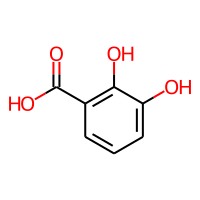
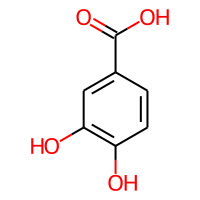
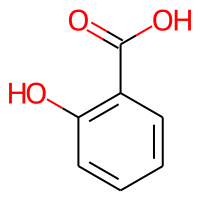
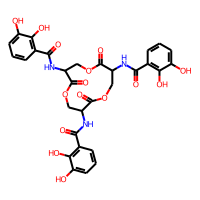
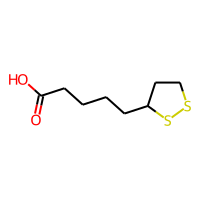
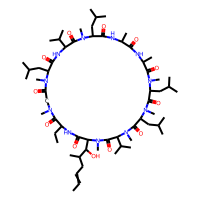
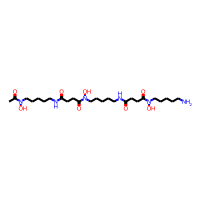
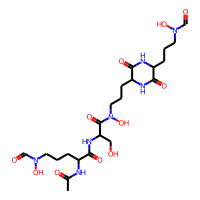
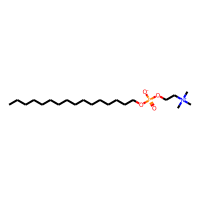
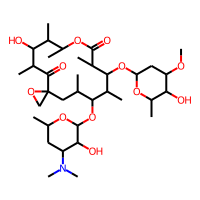
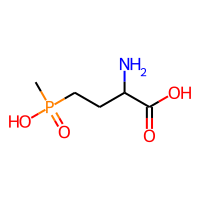
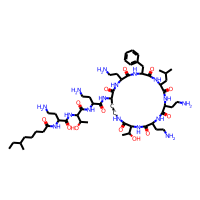
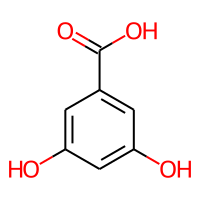
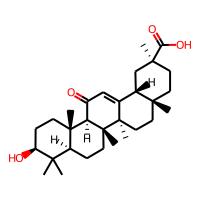
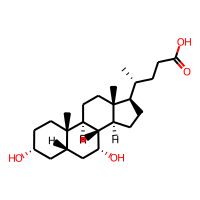

In [62]:
df_smiles.head(15)

In [64]:
folder='data/'
indexer_original_mols = {i:index for i, index in enumerate(df_smiles['ID'].values)}
#with open(folder + 'indexer_original_mols.pkl', 'wb') as f:
with open('data/' + 'indexer_original_mols_Apr23.pkl', 'wb') as f:
    pickle.dump(indexer_original_mols, f)

In [ ]:
with open('data/' + 'indexer_original_mols_Feb23.pkl', 'rb') as f:
    indexer_original_mols = pickle.load(f)

In [66]:
# Compute the molecular fingerprints and the distance matrix from the molecules, not from smiles

dim = 1024
MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

fps_molecules = MAP4.calculate_many([molecule for molecule in df_smiles['Molecule'].values])

In [67]:
distance_matrix = np.zeros((df_smiles.shape[0], 
                            df_smiles.shape[0]))

for i in range(df_smiles.shape[0]):
    for j in range(df_smiles.shape[0]):
        distance_matrix[i,j] = ENC.get_distance(fps_molecules[i], fps_molecules[j])

In [21]:
folder = 'data/'

In [83]:
distance_matrix

array([[0.        , 0.62011719, 0.53808594, ..., 1.        , 1.        ,
        0.9921875 ],
       [0.62011719, 0.        , 0.75585938, ..., 1.        , 1.        ,
        0.99414062],
       [0.53808594, 0.75585938, 0.        , ..., 1.        , 1.        ,
        0.99023438],
       ...,
       [1.        , 1.        , 1.        , ..., 0.        , 0.98535156,
        0.99902344],
       [1.        , 1.        , 1.        , ..., 0.98535156, 0.        ,
        0.99707031],
       [0.9921875 , 0.99414062, 0.99023438, ..., 0.99902344, 0.99707031,
        0.        ]])

# Export Distance Matrix

In [19]:
# THIS IS TO EXPORT THE DISTANCE MATRIX
df = pd.DataFrame(distance_matrix, index=id_uniques, columns=id_uniques)
df.to_csv('distance_matrix_Feb23.csv', index=True, header=True, sep=',')

NameError: name 'distance_matrix' is not defined

In [85]:
#with open(folder + 'distance_matrix.pkl', 'wb') as f:
with open(folder + 'distance_matrix_Feb23.pkl', 'wb') as f:
    pickle.dump(distance_matrix, f)

In [22]:
#with open(folder + 'distance_matrix.pkl', 'rb') as f:
with open(folder + 'distance_matrix_Feb23.pkl', 'rb') as f:
    distance_matrix = pickle.load(f)

In [32]:
# CARGAR MATRIZ DE DISTANCIAS
distance_matrix = pd.read_csv('similarity_matrixv4.csv', index_col=0, header=0)

In [33]:
distance_matrix

,SF_0293,SF_0298,SF_0446,SF_0197,BS_0894,BS_1574,SF_0068,SF_0401,BS_1033,BS_0042,...,SF_0707,SF_0713,SF_0708,SF_0716,SF_0706,SF_0692,SF_0690,SF_0719,SF_0714,SF_0681
SF_0293,1,0,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0298,0,1,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0446,0,0,1,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
SF_0197,0,0,0,1.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
BS_0894,0,0,0,0.0,1,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SF_0692,0,0,0,0.0,0,0.0,0.0,0.062,0,0.0,...,0.062,0.056,0.062,0.000,0.062,1.000,0.692,0.0,0.062,0
SF_0690,0,0,0,0.0,0,0.0,0.0,0.062,0,0.0,...,0.062,0.056,0.062,0.000,0.062,0.692,1.000,0.0,0.062,0
SF_0719,0,0,0,0.0,0,0.0,0.0,0.000,0,0.0,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0
SF_0714,0,0,0,0.0,0,0.0,0.0,0.714,0,0.0,...,0.714,0.556,0.714,0.056,0.333,0.062,0.062,0.0,1.000,0


In [59]:
distance_matrix = distance_matrix.applymap(lambda x: 1-x)
distance_matrix

,SF_0293,SF_0298,SF_0446,SF_0197,BS_0894,BS_1574,SF_0068,SF_0401,BS_1033,BS_0042,...,SF_0707,SF_0713,SF_0708,SF_0716,SF_0706,SF_0692,SF_0690,SF_0719,SF_0714,SF_0681
SF_0293,0,1,1,1.0,1,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0,1.000,1
SF_0298,1,0,1,1.0,1,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0,1.000,1
SF_0446,1,1,0,1.0,1,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0,1.000,1
SF_0197,1,1,1,0.0,1,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0,1.000,1
BS_0894,1,1,1,1.0,0,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.0,1.000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SF_0692,1,1,1,1.0,1,1.0,1.0,0.938,1,1.0,...,0.938,0.944,0.938,1.000,0.938,0.000,0.308,1.0,0.938,1
SF_0690,1,1,1,1.0,1,1.0,1.0,0.938,1,1.0,...,0.938,0.944,0.938,1.000,0.938,0.308,0.000,1.0,0.938,1
SF_0719,1,1,1,1.0,1,1.0,1.0,1.000,1,1.0,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.0,1.000,1
SF_0714,1,1,1,1.0,1,1.0,1.0,0.286,1,1.0,...,0.286,0.444,0.286,0.944,0.667,0.938,0.938,1.0,0.000,1




In [60]:
# VISUALIZES THE DENDROGRAM

fig = plt.figure(figsize=(30,200))
ax = fig.add_subplot()

my_model = structure_clustering(1, 'complete', distance_matrix = distance_matrix)

plot_dendrogram(my_model, ax=ax, orientation='left')

In [24]:
# NOT NEEDED
type(my_model)

sklearn.cluster._agglomerative.AgglomerativeClustering

In [44]:
# MAYBE LATER
# An example to obtain the number of clusters per defined threshold

my_model = structure_clustering(0.35534497647452307, 'complete', distance_matrix = distance_matrix)
n_clusters = get_nclusters(my_model)
n_clusters

1064

In [45]:
# LATER
np.unique(my_model.labels_)

array([   0,    1,    2, ..., 1061, 1062, 1063])

In [62]:
with open('data/' + 'cluster_labelsApr23', 'wb') as f:
    pickle.dump(my_model.labels_, f)

In [76]:
# Obtains the merging distances of the previously computed dendrogram

dendrogram_distances = get_distances(my_model)

In [48]:
len(dendrogram_distances)

1852

<AxesSubplot:ylabel='Probability'>

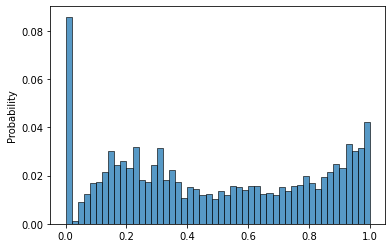

In [49]:
sns.histplot(dendrogram_distances, stat='probability', bins=50)

In [95]:
distance_matrix.shape

(1853, 1853)

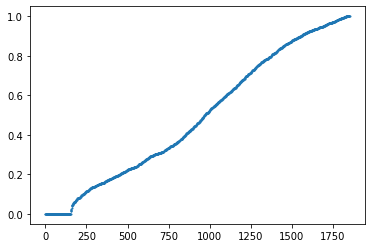

In [50]:
plt.scatter(list(range(len(dendrogram_distances))), dendrogram_distances, s=1)

In [63]:
# COMPUTES A DICTIONARY CONTAINING THE IDs IN EACH CLUSTER

clusters = get_clusters(df_smiles, my_model)
clusters

{0: [9,
  16,
  17,
  31,
  113,
  179,
  182,
  200,
  209,
  211,
  212,
  213,
  319,
  429,
  430,
  620,
  627,
  629,
  630,
  631,
  636,
  663,
  757,
  758,
  949,
  955,
  956,
  957,
  958,
  1076,
  1224,
  1243,
  1350,
  1401,
  1420,
  1443,
  1475,
  1604,
  1672,
  1673,
  1674,
  1675,
  1705,
  1757],
 1: [123,
  175,
  201,
  226,
  228,
  288,
  315,
  355,
  397,
  398,
  400,
  401,
  486,
  487,
  488,
  489,
  564,
  565,
  566,
  567,
  568,
  569,
  701,
  728,
  729,
  732,
  778,
  820,
  824,
  825,
  826,
  827,
  865,
  866,
  867,
  868,
  869,
  870,
  897,
  920,
  964,
  1017,
  1042,
  1068,
  1219,
  1254,
  1267,
  1281,
  1286,
  1289,
  1303,
  1317,
  1387,
  1389,
  1444,
  1541,
  1542,
  1547,
  1548,
  1565,
  1566,
  1593,
  1602,
  1624,
  1625,
  1626,
  1627,
  1633,
  1634,
  1637,
  1638,
  1644,
  1646,
  1670,
  1706,
  1717,
  1718,
  1791,
  1792,
  1803,
  1850],
 2: [21,
  82,
  124,
  125,
  193,
  203,
  204,
  205,
  206,
  2

<AxesSubplot:ylabel='Count'>

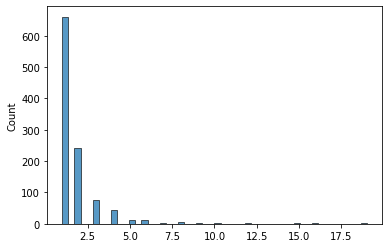

In [68]:
lst = [len(value) for key, value in clusters.items()]
sns.histplot(lst, bins=50)

In [70]:
uniques = [value for value in lst if value==1]
len(uniques)

661

In [71]:
# SHOWS THE PERCENTAGE OF THE TOTAL NUMBER OF EXAMPLES A CLUSTER REPRESENTS

size = get_cluster_size(my_model)
size

{0: 0.10793308148947653,
 1: 0.5396654074473827,
 2: 0.21586616297895306,
 3: 0.10793308148947653,
 4: 0.21586616297895306,
 5: 0.10793308148947653,
 6: 0.10793308148947653,
 7: 0.32379924446842956,
 8: 0.10793308148947653,
 9: 0.26983270372369134,
 10: 0.8634646519158122,
 11: 0.4317323259579061,
 12: 0.21586616297895306,
 13: 0.21586616297895306,
 14: 0.10793308148947653,
 15: 0.16189962223421478,
 16: 0.10793308148947653,
 17: 1.0253642741500268,
 18: 0.16189962223421478,
 19: 0.809498111171074,
 20: 0.10793308148947653,
 21: 0.16189962223421478,
 22: 0.10793308148947653,
 23: 0.16189962223421478,
 24: 0.10793308148947653,
 25: 0.16189962223421478,
 26: 0.10793308148947653,
 27: 0.21586616297895306,
 28: 0.10793308148947653,
 29: 0.16189962223421478,
 30: 0.26983270372369134,
 31: 0.10793308148947653,
 32: 0.21586616297895306,
 33: 0.21586616297895306,
 34: 0.16189962223421478,
 35: 0.16189962223421478,
 36: 0.10793308148947653,
 37: 0.10793308148947653,
 38: 0.10793308148947653,
 3

,ID,Molecule,SMILES
129,SF_0192,,CCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)c1coc(...
130,SF_0127,,CCCCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)c1co...
131,SF_0154,,CCCCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)c1co...
1095,SF_0170,,CCCCCCCCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)...
1103,SF_0138,,CCCCCCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)c1...
1107,SF_0195,,CCCCCCCCCCCCCC(OC(=O)C(CCCCN(O)C(C)=O)NC(=O)c1...

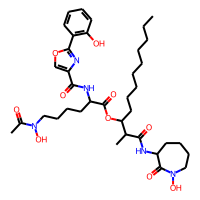
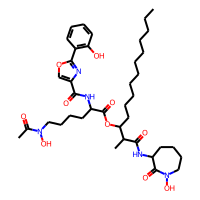
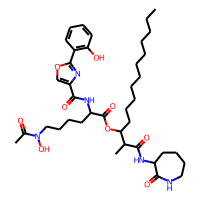
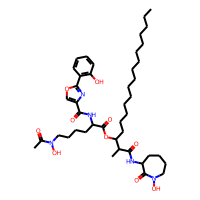
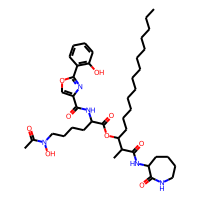
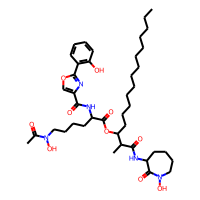

In [72]:
# GETS THE SLICE OF THE DATASET THAT CORRESPOND TO THE QUERYING CLUSTER (LAST ARGUMENT) AND SHOWS THE SMILES

cluster_df = draw_cluster(df_smiles, my_model, 7, clusters)
cluster_df

# 2. Substructure Dataset Generation V2
The use of FindMCS function by rdkit gave good results. However, special attention must be paid to initialisation

In [102]:
df_aux = df_smiles.copy()
original_molecules = []
original_smiles = []
for i in range(df_smiles.shape[0]):
    molecule = df_smiles.iloc[i]['Molecule']
    smile = df_smiles.iloc[i]['SMILES']
    original_molecules.append(molecule)
    original_smiles.append(smile)

In [103]:
#with open(folder + 'original_molecules.pkl', 'wb') as f:
with open(folder + 'original_molecules_Feb23.pkl', 'wb') as f:
    pickle.dump(original_molecules, f)

In [104]:
#with open(folder + 'original_smiles.pkl', 'wb') as f:
with open(folder + 'original_smiles_Feb23.pkl', 'wb') as f:
    pickle.dump(original_smiles, f)

In [85]:
with open('data/' + 'original_smiles_Feb23.pkl', 'rb') as f:
    original_smiles = pickle.load(f)

In [84]:
with open('data/' + 'original_molecules_Feb23.pkl', 'rb') as f:
    original_molecules = pickle.load(f)

In [66]:
complete_model = molecular_structure_clustering.structure_clustering(1, 'complete', distance_matrix = distance_matrix)

In [67]:
distance_matrix.shape

(1853, 1853)

In [68]:
children = complete_model.children_
leaves, children_new = molecular_structure_clustering.get_leaves(children)

In [69]:
#with open(folder + 'leaves.pkl', 'wb') as f:
with open('data/' + 'leaves_Apr23.pkl', 'wb') as f:
    pickle.dump(leaves, f)

In [27]:
with open(folder + 'leaves_Feb23.pkl', 'rb') as f:
    leaves = pickle.load(f)

In [4]:
with open('backups/' + 'leaves_graphs.pkl', 'rb') as f:
    leaves = pickle.load(f)

In [31]:
df_smiles.iloc[1855]

1853

In [18]:
list(leaves.values())[1740]

[1855,
 1740,
 1630,
 1550,
 1453,
 1358,
 1264,
 1178,
 1093,
 1010,
 932,
 850,
 768,
 683,
 614,
 550,
 442,
 493]

In [70]:
# INITIALIZATION

substructures_smarts, substructures_molecules, substructures_cancelations = molecular_structure_clustering.get_substructure_list(df_smiles, leaves, rings=False)

In [71]:
#with open(folder + 'substructures_smarts_init.pkl', 'wb') as f:
with open('data/' + 'substructures_smarts_init_Apr23.pkl', 'wb') as f:
    pickle.dump(substructures_smarts, f)

In [28]:
with open(folder + 'substructures_smarts_init_Feb23.pkl', 'rb') as f:
    substructures_smarts_init = pickle.load(f)

In [118]:
len([item for item in substructures_cancelations if item])/len(substructures_cancelations)*100

0.0

In [72]:
with open('data/' + 'substructures_smarts_Apr23.pkl', 'wb') as f:
    pickle.dump(substructures_smarts, f)

In [73]:
with open('data/' + 'substructures_molecules_Apr23.pkl', 'wb') as f:
    pickle.dump(substructures_molecules, f)

In [29]:
with open('data/' + 'substructures_smarts_Apr23.pkl', 'rb') as f:
    substructures_smarts = pickle.load(f)

In [30]:
with open('data/' + 'substructures_molecules_Apr23.pkl', 'rb') as f:
    substructures_molecules = pickle.load(f)

# 4. Optimum Distance Determination
This section is dedicated to analise results for every cluster taking into account the modified silhouette coefficient

In [74]:
def get_brothers(df_smiles, leaves, distance_matrix, distances, linkage='complete'):
    brothers = {}
    n_samples = len(distances) +1
    for node, distance in enumerate(distances):
        
        node  = node + n_samples
        print("Computing node " + str(node), end="\r")
        
        brothers[node] = []
        trained_model = structure_clustering(distance, linkage, distance_matrix = distance_matrix)
        clusters = get_clusters(df_smiles, trained_model)
        
        for key, value in clusters.items():
            flag= True
            
            if len(value) == 1:
                brothers[node].append(value[0])
                flag=False
            else:
                for key_2, value_2 in leaves.items():
                    if set(value) == set(value_2):
                        brothers[node].append(key_2)
                        flag=False
            if flag:
                print('ERROR: Cluster ' + str(key) + ' not identified.')
                
    return brothers

In [77]:
brothers = get_brothers(df_smiles, leaves, distance_matrix, dendrogram_distances, linkage='complete')

In [78]:
with open('data/' + 'brothers_Apr23.json', 'w') as outfile:
    json.dump(brothers, outfile)

In [79]:
with open('data/' + 'brothers_Apr23.json', 'r') as outfile:
    brothers = json.load(outfile)
    
for key in brothers.keys():
    brothers[int(key)] = brothers.pop(key)
for key in brothers.keys():
    brothers[int(key)] = brothers.pop(key)
set(brothers.keys()) == set(range(1853, 3704))

False

In [80]:
from map4 import MAP4Calculator
import tmap as tm

In [87]:
dim = 1024
MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

n_samples = df_smiles.shape[0]

# Computes the Fingerprints of the substructures
fps_substructures = MAP4.calculate_many(substructures_molecules)
fps_molecules = MAP4.calculate_many(original_molecules)


In [82]:
def mcs_silhouette(distance_index, fps_molecules, fps_substructures, brothers, config='mol2MCS'):
    
    '''
    n_samples-1 possible clustering models, distance index is the index of the distance in dendrogam
    defining the corresponding cluster. It is as well the highest node of the model.
    '''
    a = []
    b = []
    s = []
    isol = 0
    n_samples = len(fps_molecules)
    brothers_i = brothers[distance_index + n_samples]
    n_clusters = len(brothers_i)
    for i in range(n_samples):
        #print(f'Calculating the molecule [{i+1}/{n_samples}]', end='\r')
        flag = True
        for brother in brothers_i:
            try:
                if i in leaves[brother]:
                    node = brother # The node at which i belongs
                    flag=False
                    is_isolated=False
                    break
            except:
                if i == brother:
                    isol += 1
                    node = brother
                    is_isolated = True
                    flag=False
                    break
        
        if flag:
            print("A molecule was not identified in any cluster")
        
        if is_isolated:
            #s.append(0)
            a.append(0)
            b.append(0)
            s.append(0)
            continue
        else:
            # TODO: THIS WILL BE JACCARD BETWEEN ORIGINAL GRAPH AND INTERSECTION GRAPH
            a.append(ENC.get_distance(fps_molecules[i], fps_substructures[node-n_samples]))
            #b.append(0)
            #continue
            
        #a.append(ENC.get_distance(fps_molecules[i], fps_substructures[node-n_samples]))
        
        b_temp=[]
        for brother in brothers_i:
            if brother == node:
                continue
            if brother >= n_samples:
                if config == 'mol2MCS':
                    b_temp.append(ENC.get_distance(fps_molecules[i], fps_substructures[brother-n_samples]))
                else:
                    b_temp.append(ENC.get_distance(fps_substructures[node-n_samples], fps_substructures[brother-n_samples]))
            else:
                if config=='mol2MCS':
                    b_temp.append(ENC.get_distance(fps_substructures[node-n_samples], fps_molecules[brother]))
                else:
                    b_temp.append(ENC.get_distance(fps_molecules[i], fps_molecules[brother]))
        
        b.append(np.min(b_temp))
        s_temp = (b[i]-a[i])/np.max([a[i], b[i]])
        if s_temp == s_temp:
            s.append(s_temp)
        else:
            s.append(0)
    
    results = {
        'mean_silhouette':np.mean(s),
        'isolated_mols': isol,
        'n_clusters': n_clusters,
        'mean_a': np.mean(a),
        'mean_b': np.mean(b),
    }
    
    return results
            

In [88]:
results = []
for j in range(len(original_molecules)-1):
    print(f'Evaluating model: [{j}/{len(original_molecules)-1}]', end='\r')
    # fps_molecules WILL BE ORIGINAL GRAPHS AND fps_substructures WILL BE INTERSECTION GRAPHS
    results_j = mcs_silhouette(j, fps_molecules, fps_substructures, brothers)
    results.append(results_j)
    

In [89]:
with open('data/' + 'silhouette_results_Apr23.pkl', 'wb') as f:
    pickle.dump(results, f)

In [34]:
with open('data/' + 'silhouette_results_Apr23.pkl', 'rb') as f:
    results = pickle.load(f)

Text(0, 0.5, 'Scaled Modified Silhouette Coefficient')

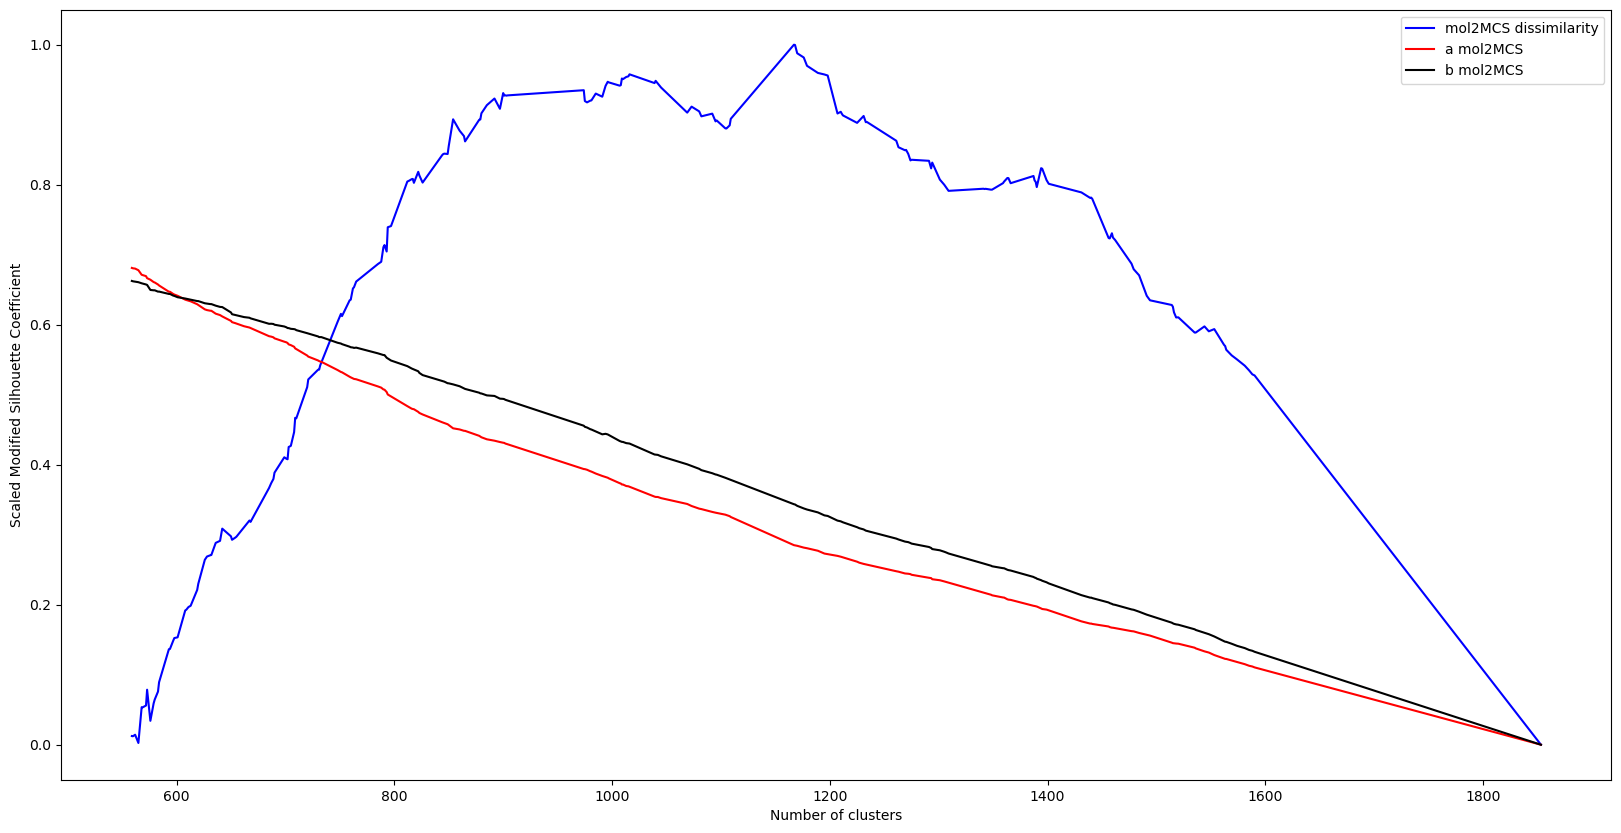

In [90]:
fig, axis = plt.subplots(figsize=(20, 10))
X = np.abs(np.array([v['mean_silhouette'] for v in results]))
X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
X_scaled = X_std * (1 - 0) + 0

axis.plot([v['n_clusters'] for v in results], X_scaled, label='mol2MCS dissimilarity', color='blue')

axis.plot([v['n_clusters'] for v in results], [v['mean_a'] for v in results], label='a mol2MCS', color='red')
axis.plot([v['n_clusters'] for v in results], [v['mean_b'] for v in results], label='b mol2MCS', color='black')
axis.legend()
axis.set_xlabel('Number of clusters')
axis.set_ylabel('Scaled Modified Silhouette Coefficient')

Text(0, 0.5, 'Scaled Modified Silhouette Coefficient')

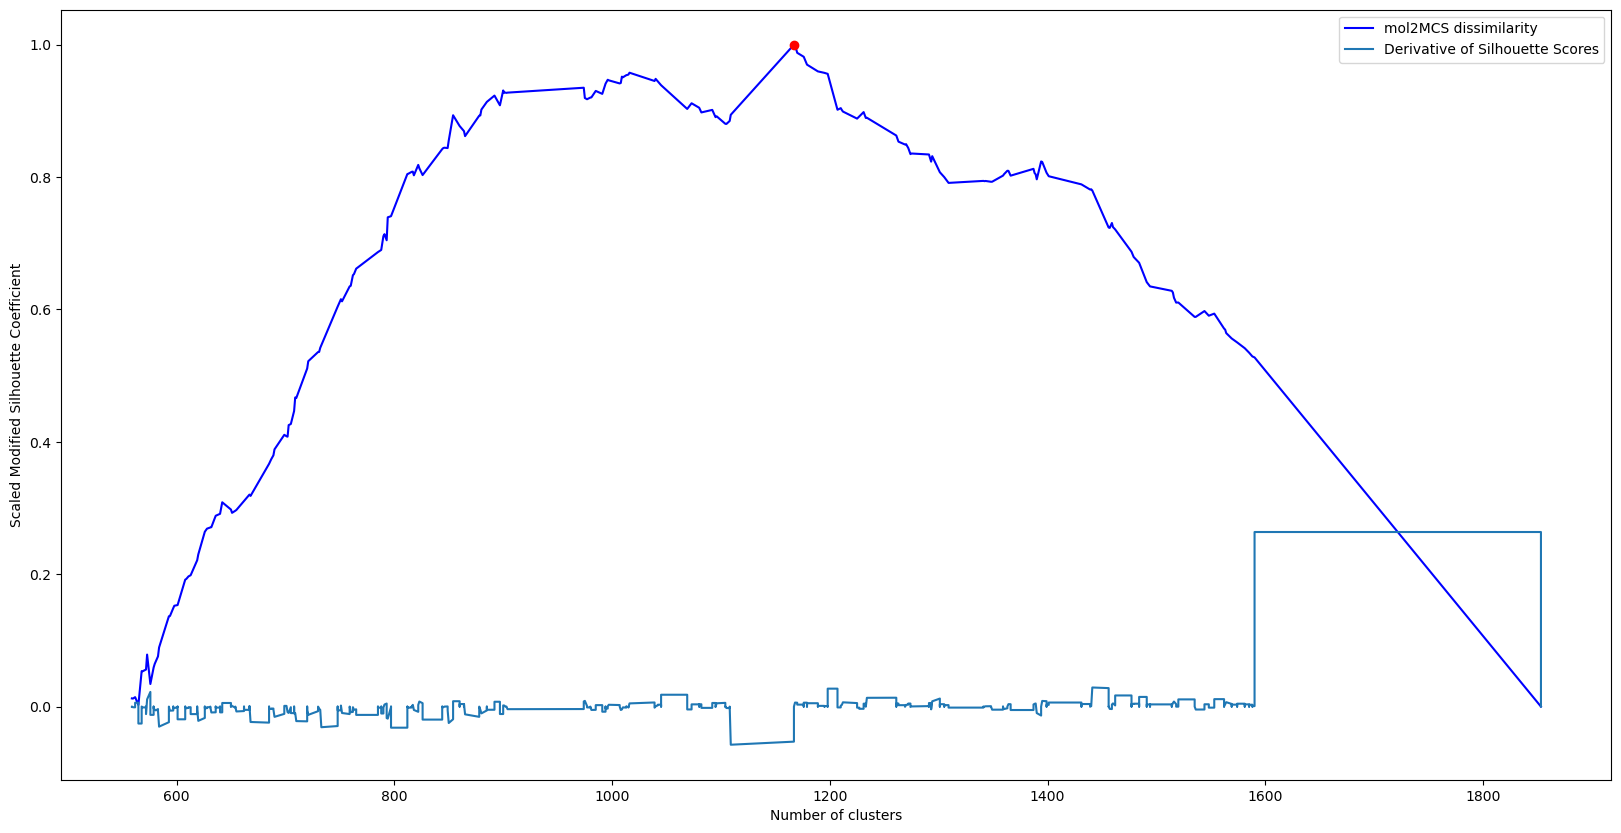

In [91]:
fig, axis = plt.subplots(figsize=(20, 10))
X = np.abs(np.array([v['mean_silhouette'] for v in results]))
X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
X_scaled = X_std * (1 - 0) + 0

# Compute the derivative of the silhouette scores
gradient = np.gradient(X_scaled)  # Find the index of the maximum value of the silhouette scores
max_index = np.argmax(X_scaled)   # Find the index of the first zero-crossing of the derivative
#ip = np.where(np.abs(gradient) < 0.00001)[0]
zeros = np.where(np.diff(np.sign(gradient)))[0]
max_derivative_index = zeros[0] # Plot the silhouette scores, derivative, and maximum point

axis.plot([v['n_clusters'] for v in results], X_scaled, label='mol2MCS dissimilarity', color='blue')
axis.plot([v['n_clusters'] for v in results], gradient, label='Derivative of Silhouette Scores')
axis.plot([v['n_clusters'] for v in results][max_index], X_scaled[max_index],'o',color='red')
axis.legend()
axis.set_xlabel('Number of clusters')
axis.set_ylabel('Scaled Modified Silhouette Coefficient')

In [98]:
max_index

686

In [118]:
dendrogram_distances[686]

0.5

In [99]:
ip

NameError: name 'ip' is not defined

In [136]:
%matplotlib notebook

Text(0.5, 1.0, 'Silhouette Analysis')

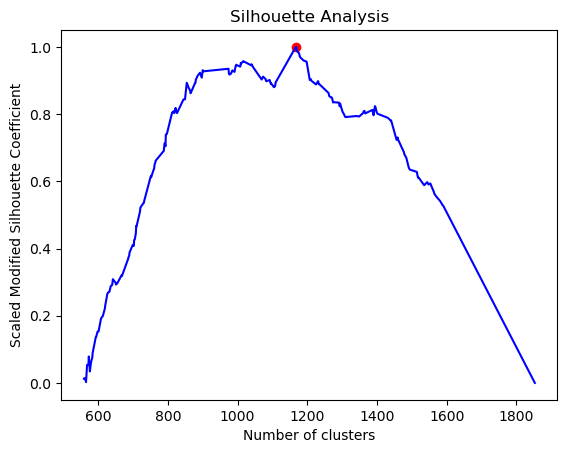

In [113]:
fig, axis = plt.subplots()

axis.plot([v['n_clusters'] for v in results][max_index], X_scaled[max_index], 'o',color='red')
axis.plot([v['n_clusters'] for v in results], X_scaled, color='blue')
axis.set_xlabel('Number of clusters')
axis.set_ylabel('Scaled Modified Silhouette Coefficient')
axis.set_title('Silhouette Analysis')

In [115]:
X[max_index]

0.105839042973295

In [143]:
np.argsort([v['mean_silhouette'] for v in results])[-600:]

array([1567, 1566, 1565, 1564, 1573,  310,  311,  307,  306,  309,  308,
       1569, 1572, 1570, 1568, 1571,  305,  304, 1575, 1576, 1577, 1574,
        303,  302,  301, 1579, 1578, 1583, 1580, 1581, 1582, 1584,  300,
        299, 1593, 1594, 1595, 1592,  295,  296,  298,  297, 1591, 1586,
       1585,  292,  289,  293,  290,  294,  291, 1588, 1587, 1589, 1590,
        287,  288,  286, 1597, 1598, 1596, 1604, 1605, 1609, 1608, 1607,
       1606, 1603, 1600, 1601, 1602, 1599,  285,  284,  283,  282, 1610,
       1611, 1612,  281, 1613, 1614, 1615, 1616, 1617, 1618, 1619, 1620,
        280,  279,  278, 1621, 1622, 1623, 1627, 1624, 1625, 1626, 1628,
       1632, 1633, 1634, 1635, 1629, 1631, 1630,  274,  275,  276,  277,
       1636, 1637, 1638,  273,  271,  272, 1639, 1640, 1641, 1642, 1644,
       1649, 1648, 1647, 1646, 1643, 1645,  269,  270,  268,  267,  265,
        266,  264, 1650, 1651, 1653, 1654, 1655, 1652,  263,  262, 1657,
       1656,  261,  260,  259, 1658, 1659, 1660, 16

In [101]:
max_index

686

In [102]:
dendrogram_distances[927]

0.667

In [103]:
[v['n_clusters'] for v in results][927]

974

Text(0, 0.5, 'value')

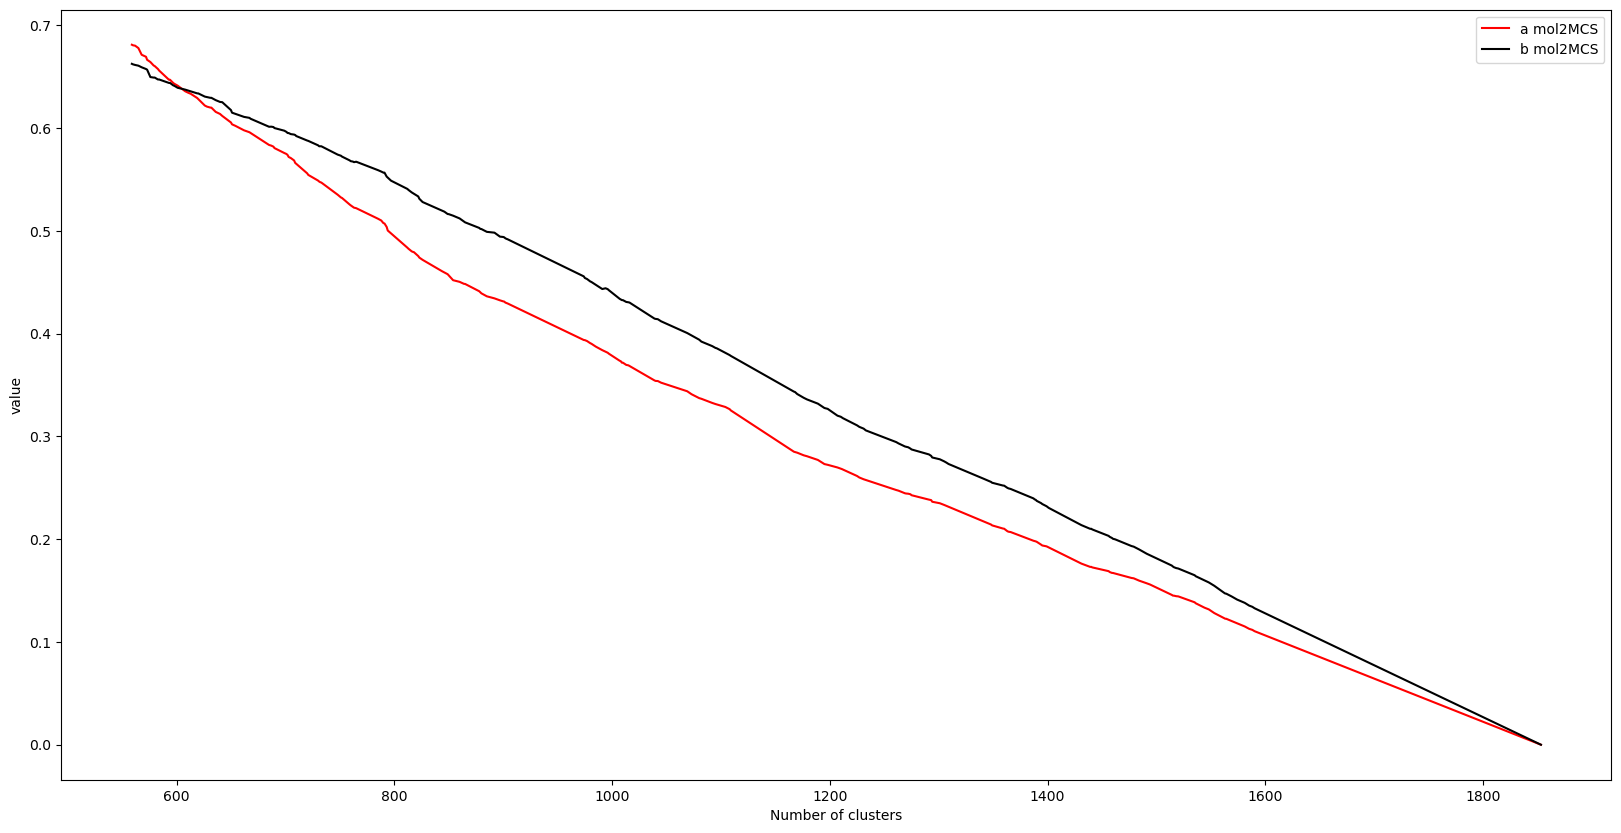

In [104]:
fig, axis = plt.subplots(figsize=(20, 10))

axis.plot([v['n_clusters'] for v in results], [v['mean_a'] for v in results], label='a mol2MCS', color='red')

axis.plot([v['n_clusters'] for v in results], [v['mean_b'] for v in results], label='b mol2MCS', color='black')
axis.legend()
axis.set_xlabel('Number of clusters')
axis.set_ylabel('value')

<IPython.core.display.Javascript object>


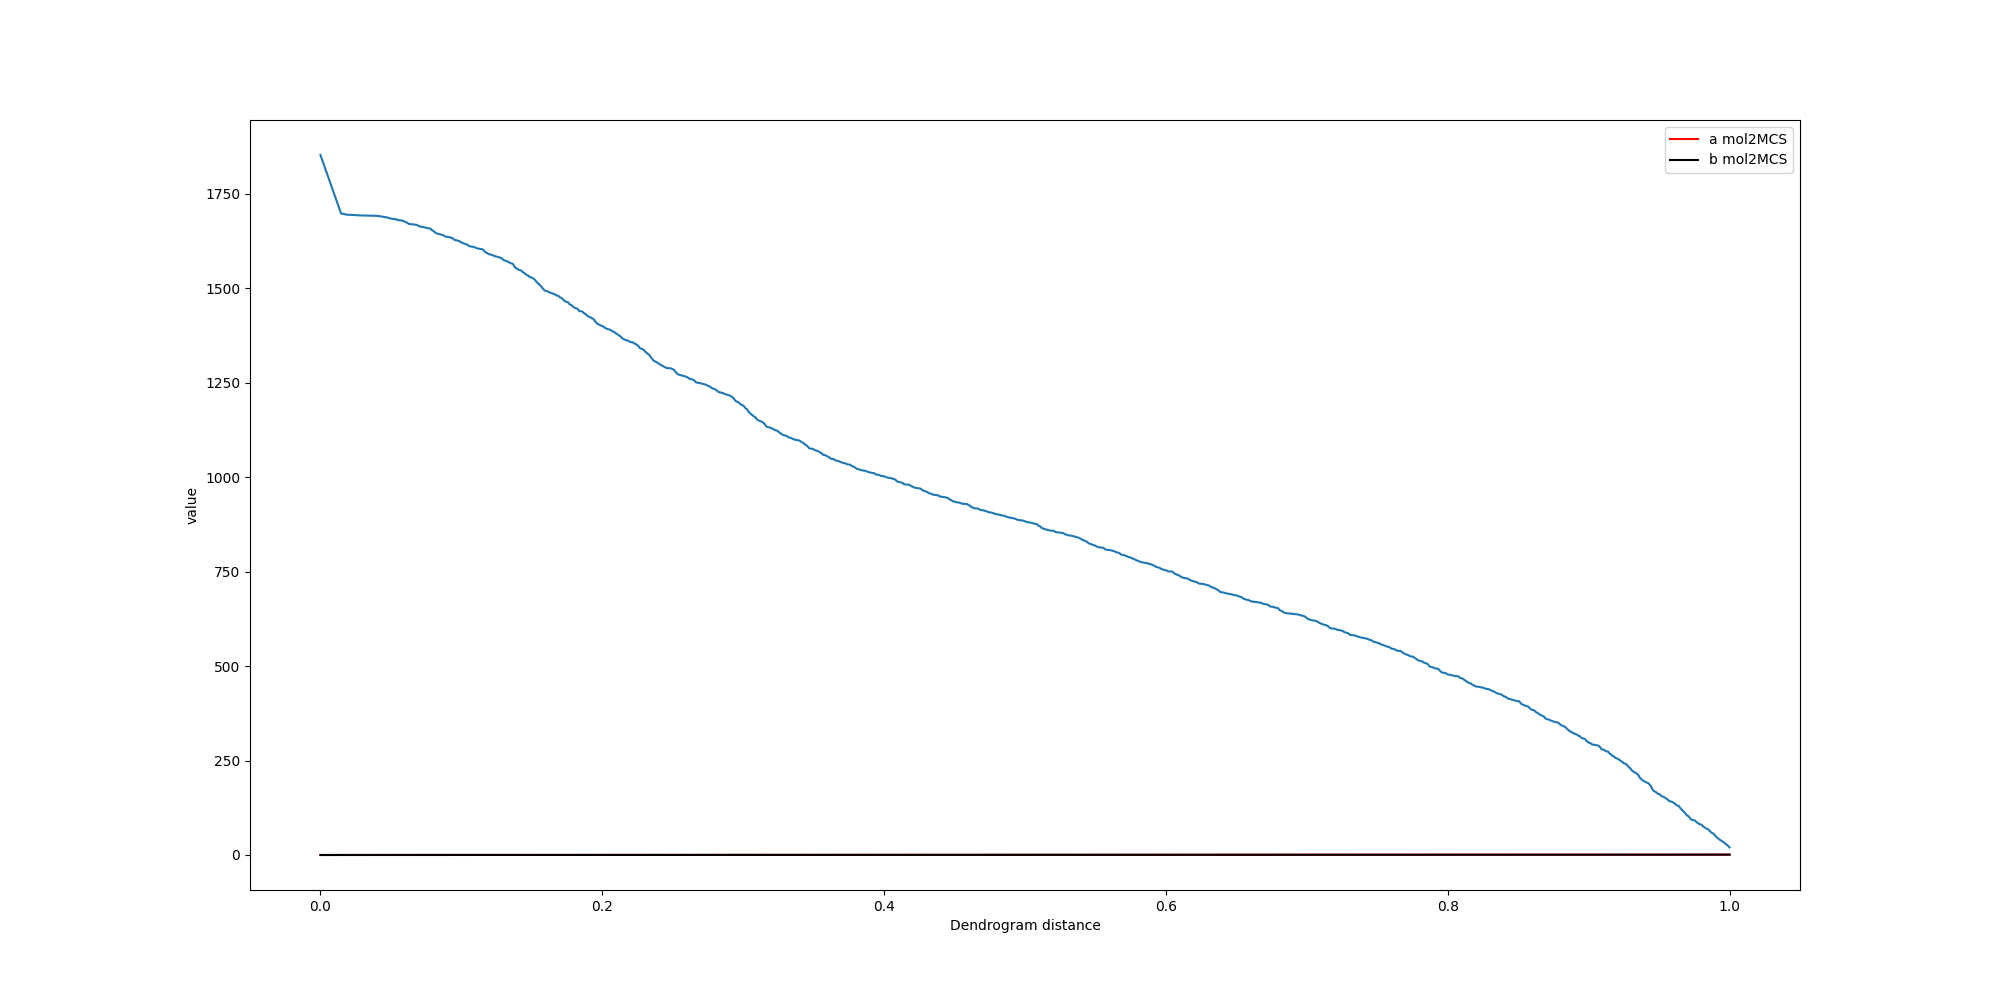

Text(0, 0.5, 'value')

In [93]:
fig, axis = plt.subplots(figsize=(20, 10))

axis.plot(dendrogram_distances, [v['mean_a'] for v in results], label='a mol2MCS', color='red')

axis.plot(dendrogram_distances, [v['mean_b'] for v in results], label='b mol2MCS', color='black')
axis.legend()
axis.set_xlabel('Dendrogram distance')
axis.set_ylabel('value')

Text(0, 0.5, 'value')

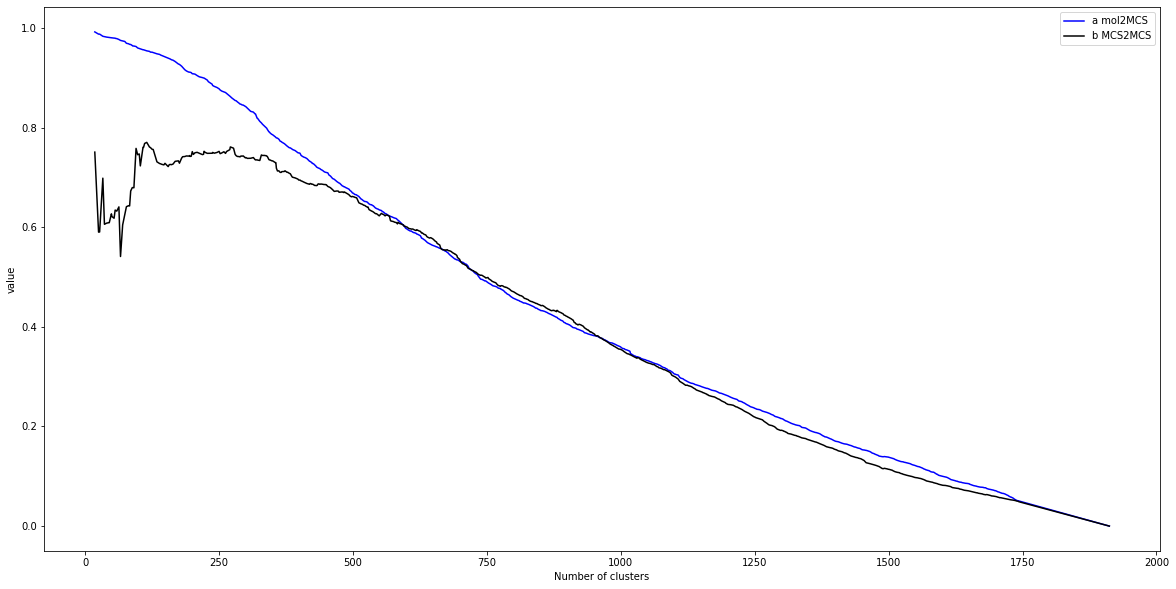

In [58]:
fig, axis = plt.subplots(figsize=(20, 10))

axis.plot([v['n_clusters'] for v in results_MCS], [v['mean_a'] for v in results_MCS], label='a mol2MCS', color='blue')

axis.plot([v['n_clusters'] for v in results_MCS], [v['mean_b'] for v in results_MCS], label='b MCS2MCS', color='black')
axis.legend()
axis.set_xlabel('Number of clusters')
axis.set_ylabel('value')

Text(0, 0.5, 'value')

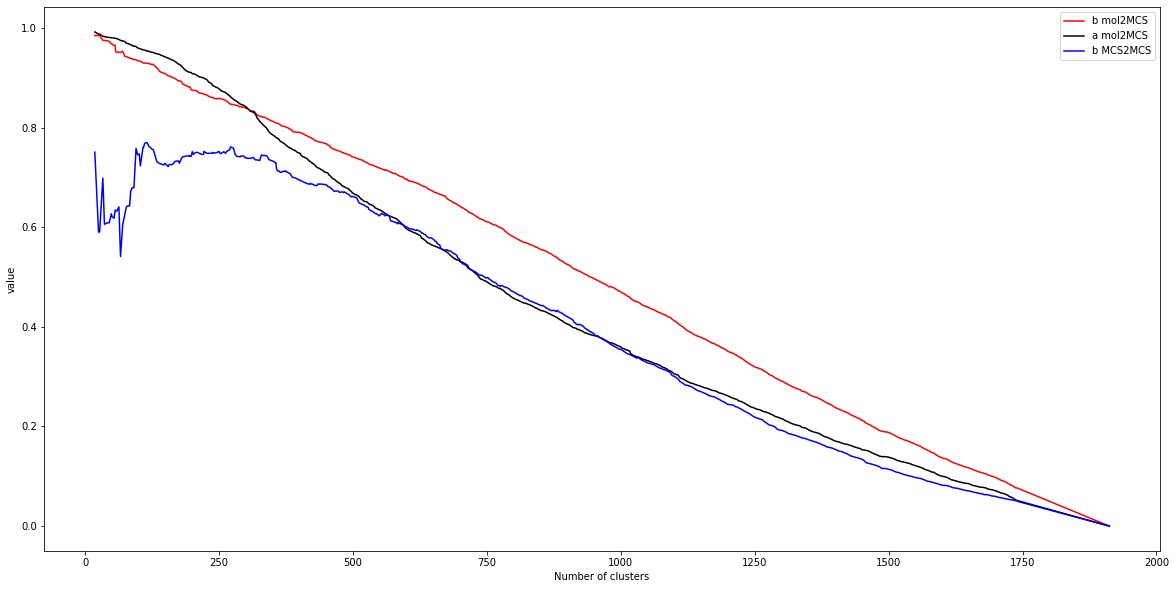

In [59]:
fig, axis = plt.subplots(figsize=(20, 10))

axis.plot([v['n_clusters'] for v in results], [v['mean_b'] for v in results], label='b mol2MCS', color='red')
axis.plot([v['n_clusters'] for v in results], [v['mean_a'] for v in results], label='a mol2MCS', color='black')
axis.plot([v['n_clusters'] for v in results_MCS], [v['mean_b'] for v in results_MCS], label='b MCS2MCS', color='blue')
axis.legend()

axis.set_xlabel('Number of clusters')
axis.set_ylabel('value')

Text(0, 0.5, 'value')

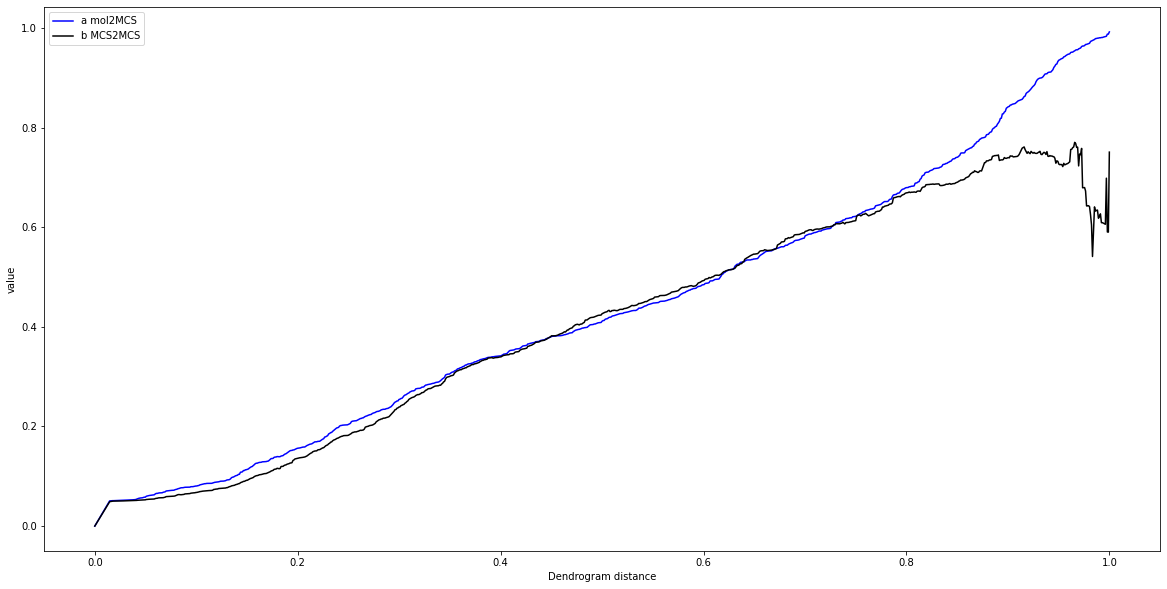

In [60]:
fig, axis = plt.subplots(figsize=(20, 10))

axis.plot(dendrogram_distances,[v['mean_a'] for v in results_MCS], label='a mol2MCS', color='blue')

axis.plot(dendrogram_distances, [v['mean_b'] for v in results_MCS], label='b MCS2MCS', color='black')
axis.legend()
axis.set_xlabel('Dendrogram distance')
axis.set_ylabel('value')

In [68]:
df_new = df_smiles.copy()
df_new.reset_index(inplace=True)
distance_matrix_names = pd.DataFrame(1-distance_matrix, columns=df_new.ID.unique(), index=df_new.ID.unique())
distance_matrix_names.head()

,BS_0002,BS_0003,BS_0004,BS_0008,BS_0011,BS_0026,BS_0031,BS_0032,BS_0033,BS_0034,...,SF_0658,SF_0659,SF_0660,SF_0661,SF_0662,SF_0663,SF_0664,SF_0665,SF_0666,SF_0667
BS_0002,1.000000,0.640625,0.730469,0.018555,0.023438,0.026367,0.000977,0.017578,0.015625,0.015625,...,0.008789,0.0,0.0,0.0,0.0,0.004883,0.004883,0.001953,0.049805,0.045898
BS_0003,0.640625,1.000000,0.484375,0.019531,0.023438,0.027344,0.000000,0.021484,0.019531,0.018555,...,0.004883,0.0,0.0,0.0,0.0,0.005859,0.005859,0.000977,0.046875,0.044922
BS_0004,0.730469,0.484375,1.000000,0.023438,0.027344,0.025391,0.001953,0.019531,0.018555,0.017578,...,0.007812,0.0,0.0,0.0,0.0,0.004883,0.004883,0.002930,0.052734,0.047852
BS_0008,0.018555,0.019531,0.023438,1.000000,0.226562,0.178711,0.047852,0.272461,0.294922,0.244141,...,0.000977,0.0,0.0,0.0,0.0,0.003906,0.003906,0.005859,0.013672,0.019531
BS_0011,0.023438,0.023438,0.027344,0.226562,1.000000,0.198242,0.049805,0.177734,0.191406,0.174805,...,0.002930,0.0,0.0,0.0,0.0,0.000977,0.000977,0.004883,0.010742,0.017578


In [69]:
distance_matrix_names.to_csv('v2_files/jaccard_similarity.csv')

# 5. MCS validation

In [73]:
dim = 1024
MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

n_samples = df_smiles.shape[0]

# Computes the Fingerprints of the substructures and the nodes
fps_substructures = MAP4.calculate_many(substructures_molecules)
fps_molecules = MAP4.calculate_many(original_molecules)

In [74]:
distances_sub_lst_complete = []
distances_sub_lst = []
dendrogram_new= []
for substructure, cluster in leaves.items():
    print(substructure, end='\r')
    distance_sub = []
    for molecule in cluster:
        distance_sub.append(ENC.get_distance(fps_substructures[int(substructure) - n_samples], fps_molecules[molecule]))
    
    distances_sub_lst_complete.append(distance_sub)
    distances_sub_lst.append(np.mean(np.array(distance_sub)))

In [80]:
#distances_sub_lst_complete = np.load('MCS_distances_average.npy', allow_pickle=True)

In [79]:
warnings.filterwarnings('ignore')
linkage= 'complete'
similaritites, n_clusters_lst = get_substructures_similarities_map4(df_smiles, distances_sub_lst_complete, leaves, children_new, distance_matrix, dendrogram_distances, linkage=linkage)

PROGRESS: 0.0
PROGRESS: 0.05399568034557236
PROGRESS: 0.10799136069114472
PROGRESS: 0.16198704103671707
PROGRESS: 0.21598272138228944
PROGRESS: 0.26997840172786175
PROGRESS: 0.32397408207343414
PROGRESS: 0.3779697624190065
PROGRESS: 0.4319654427645789
PROGRESS: 0.48596112311015116
PROGRESS: 0.5399568034557235
PROGRESS: 0.593952483801296
PROGRESS: 0.6479481641468683
PROGRESS: 0.7019438444924406
PROGRESS: 0.755939524838013
PROGRESS: 0.8099352051835854
PROGRESS: 0.8639308855291578
PROGRESS: 0.9179265658747301
PROGRESS: 0.9719222462203023
PROGRESS: 1.0259179265658747
PROGRESS: 1.079913606911447
PROGRESS: 1.1339092872570196
PROGRESS: 1.187904967602592
PROGRESS: 1.2419006479481642
PROGRESS: 1.2958963282937366
PROGRESS: 1.349892008639309
PROGRESS: 1.4038876889848813
PROGRESS: 1.4578833693304536
PROGRESS: 1.511879049676026
PROGRESS: 1.565874730021598
PROGRESS: 1.6198704103671708
PROGRESS: 1.6738660907127432
PROGRESS: 1.7278617710583155
PROGRESS: 1.7818574514038878
PROGRESS: 1.8358531317494602


PROGRESS: 15.604751619870411
PROGRESS: 15.658747300215984
PROGRESS: 15.712742980561556
PROGRESS: 15.766738660907128
PROGRESS: 15.820734341252699
PROGRESS: 15.874730021598271
PROGRESS: 15.928725701943844
PROGRESS: 15.982721382289416
PROGRESS: 16.036717062634988
PROGRESS: 16.09071274298056
PROGRESS: 16.144708423326133
PROGRESS: 16.19870410367171
PROGRESS: 16.25269978401728
PROGRESS: 16.30669546436285
PROGRESS: 16.360691144708422
PROGRESS: 16.414686825053995
PROGRESS: 16.468682505399567
PROGRESS: 16.52267818574514
PROGRESS: 16.57667386609071
PROGRESS: 16.630669546436287
PROGRESS: 16.68466522678186
PROGRESS: 16.738660907127432
PROGRESS: 16.792656587473
PROGRESS: 16.846652267818573
PROGRESS: 16.900647948164146
PROGRESS: 16.954643628509718
PROGRESS: 17.00863930885529
PROGRESS: 17.062634989200866
PROGRESS: 17.11663066954644
PROGRESS: 17.17062634989201
PROGRESS: 17.22462203023758
PROGRESS: 17.278617710583152
PROGRESS: 17.332613390928724
PROGRESS: 17.386609071274297
PROGRESS: 17.44060475161987


PROGRESS: 31.101511879049674
PROGRESS: 31.155507559395247
PROGRESS: 31.209503239740823
PROGRESS: 31.26349892008639
PROGRESS: 31.317494600431967
PROGRESS: 31.371490280777536
PROGRESS: 31.425485961123112
PROGRESS: 31.47948164146868
PROGRESS: 31.533477321814257
PROGRESS: 31.587473002159825
PROGRESS: 31.641468682505398
PROGRESS: 31.695464362850974
PROGRESS: 31.749460043196542
PROGRESS: 31.80345572354212
PROGRESS: 31.857451403887687
PROGRESS: 31.911447084233263
PROGRESS: 31.96544276457883
PROGRESS: 32.01943844492441
PROGRESS: 32.073434125269976
PROGRESS: 32.12742980561555
PROGRESS: 32.18142548596112
PROGRESS: 32.23542116630669
PROGRESS: 32.289416846652266
PROGRESS: 32.34341252699784
PROGRESS: 32.39740820734342
PROGRESS: 32.45140388768898
PROGRESS: 32.50539956803456
PROGRESS: 32.55939524838013
PROGRESS: 32.6133909287257
PROGRESS: 32.66738660907127
PROGRESS: 32.721382289416844
PROGRESS: 32.77537796976242
PROGRESS: 32.82937365010799
PROGRESS: 32.88336933045357
PROGRESS: 32.937365010799134
PROG

PROGRESS: 46.868250539956804
PROGRESS: 46.92224622030238
PROGRESS: 46.97624190064795
PROGRESS: 47.03023758099352
PROGRESS: 47.084233261339094
PROGRESS: 47.138228941684666
PROGRESS: 47.19222462203024
PROGRESS: 47.24622030237581
PROGRESS: 47.30021598272138
PROGRESS: 47.354211663066955
PROGRESS: 47.40820734341253
PROGRESS: 47.4622030237581
PROGRESS: 47.51619870410367
PROGRESS: 47.570194384449245
PROGRESS: 47.62419006479482
PROGRESS: 47.67818574514039
PROGRESS: 47.73218142548596
PROGRESS: 47.786177105831534
PROGRESS: 47.840172786177106
PROGRESS: 47.89416846652268
PROGRESS: 47.94816414686825
PROGRESS: 48.00215982721382
PROGRESS: 48.056155507559396
PROGRESS: 48.11015118790497
PROGRESS: 48.16414686825054
PROGRESS: 48.21814254859611
PROGRESS: 48.272138228941685
PROGRESS: 48.32613390928726
PROGRESS: 48.38012958963283
PROGRESS: 48.4341252699784
PROGRESS: 48.488120950323975
PROGRESS: 48.54211663066955
PROGRESS: 48.59611231101512
PROGRESS: 48.65010799136069
PROGRESS: 48.704103671706264
PROGRESS: 4

PROGRESS: 62.580993520518355
PROGRESS: 62.634989200863934
PROGRESS: 62.68898488120951
PROGRESS: 62.74298056155507
PROGRESS: 62.79697624190065
PROGRESS: 62.850971922246224
PROGRESS: 62.90496760259179
PROGRESS: 62.95896328293736
PROGRESS: 63.01295896328294
PROGRESS: 63.06695464362851
PROGRESS: 63.12095032397408
PROGRESS: 63.17494600431965
PROGRESS: 63.22894168466523
PROGRESS: 63.282937365010795
PROGRESS: 63.33693304535637
PROGRESS: 63.39092872570195
PROGRESS: 63.44492440604752
PROGRESS: 63.498920086393085
PROGRESS: 63.55291576673866
PROGRESS: 63.60691144708424
PROGRESS: 63.66090712742981
PROGRESS: 63.714902807775374
PROGRESS: 63.76889848812095
PROGRESS: 63.822894168466526
PROGRESS: 63.87688984881209
PROGRESS: 63.93088552915766
PROGRESS: 63.98488120950324
PROGRESS: 64.03887688984882
PROGRESS: 64.09287257019439
PROGRESS: 64.14686825053995
PROGRESS: 64.20086393088553
PROGRESS: 64.2548596112311
PROGRESS: 64.30885529157668
PROGRESS: 64.36285097192224
PROGRESS: 64.41684665226782
PROGRESS: 64.4

PROGRESS: 78.50971922246221
PROGRESS: 78.56371490280777
PROGRESS: 78.61771058315334
PROGRESS: 78.67170626349892
PROGRESS: 78.7257019438445
PROGRESS: 78.77969762419006
PROGRESS: 78.83369330453563
PROGRESS: 78.88768898488121
PROGRESS: 78.94168466522679
PROGRESS: 78.99568034557235
PROGRESS: 79.04967602591793
PROGRESS: 79.1036717062635
PROGRESS: 79.15766738660908
PROGRESS: 79.21166306695464
PROGRESS: 79.26565874730022
PROGRESS: 79.31965442764579
PROGRESS: 79.37365010799135
PROGRESS: 79.42764578833693
PROGRESS: 79.48164146868251
PROGRESS: 79.53563714902808
PROGRESS: 79.58963282937364
PROGRESS: 79.64362850971922
PROGRESS: 79.6976241900648
PROGRESS: 79.75161987041037
PROGRESS: 79.80561555075593
PROGRESS: 79.85961123110151
PROGRESS: 79.91360691144709
PROGRESS: 79.96760259179266
PROGRESS: 80.02159827213823
PROGRESS: 80.0755939524838
PROGRESS: 80.12958963282938
PROGRESS: 80.18358531317494
PROGRESS: 80.23758099352052
PROGRESS: 80.29157667386609
PROGRESS: 80.34557235421165
PROGRESS: 80.39956803455

PROGRESS: 94.43844492440606
PROGRESS: 94.49244060475162
PROGRESS: 94.54643628509719
PROGRESS: 94.60043196544277
PROGRESS: 94.65442764578835
PROGRESS: 94.70842332613391
PROGRESS: 94.76241900647948
PROGRESS: 94.81641468682506
PROGRESS: 94.87041036717062
PROGRESS: 94.9244060475162
PROGRESS: 94.97840172786177
PROGRESS: 95.03239740820734
PROGRESS: 95.08639308855291
PROGRESS: 95.14038876889849
PROGRESS: 95.19438444924407
PROGRESS: 95.24838012958963
PROGRESS: 95.3023758099352
PROGRESS: 95.35637149028078
PROGRESS: 95.41036717062636
PROGRESS: 95.46436285097192
PROGRESS: 95.51835853131749
PROGRESS: 95.57235421166307
PROGRESS: 95.62634989200865
PROGRESS: 95.68034557235421
PROGRESS: 95.73434125269978
PROGRESS: 95.78833693304536
PROGRESS: 95.84233261339092
PROGRESS: 95.8963282937365
PROGRESS: 95.95032397408207
PROGRESS: 96.00431965442765
PROGRESS: 96.05831533477321
PROGRESS: 96.11231101511879
PROGRESS: 96.16630669546437
PROGRESS: 96.22030237580994
PROGRESS: 96.2742980561555
PROGRESS: 96.32829373650

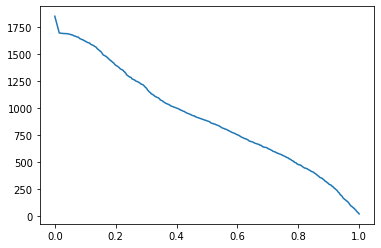

In [80]:
plt.plot(dendrogram_distances, n_clusters_lst)

In [81]:
with open('v1_files/similarities_Feb23.pkl', 'wb') as f:
    pickle.dump(similaritites, f)

In [82]:
with open('v1_files/n_clusters_Feb23.pkl', 'wb') as f:
    pickle.dump(n_clusters_lst, f)

In [84]:
with open('v1_files/similarities_Feb23.pkl', 'rb') as f:
    similarities = pickle.load(f)

In [85]:
with open('v1_files/n_clusters_Feb23.pkl', 'rb') as f:
    n_clusters_lst = pickle.load(f)

In [86]:
similarities_mean_lst = []
for i, element_1 in enumerate(similarities):
    similarities_mean = []
    for j, element_2 in enumerate(element_1):
        if len(element_2) == 0:
            continue
        similarities_mean.append(np.mean(np.array(element_2)))
    
    similarities_mean_lst.append(similarities_mean)

In [87]:
# Compute some statistics about the data obtained

means_arr = np.zeros((len(similarities_mean_lst), )) 
stds_arr = np.zeros((len(similarities_mean_lst), ))
percentile_5 = np.zeros((len(similarities_mean_lst), ))
percentile_95 = np.zeros((len(similarities_mean_lst), ))
sem = np.zeros((len(similarities_mean_lst), ))

for i, lst in enumerate(similarities_mean_lst):
    arr = np.array(lst)
    sem[i] = scipy.stats.sem(lst)
    means_arr[i] = np.mean(arr)
    stds_arr[i] = np.std(arr)
    percentile_5[i] = np.percentile(arr, 40)
    percentile_95[i] = np.percentile(arr, 60)

Text(0.5, 0, 'Dendrogram distance')

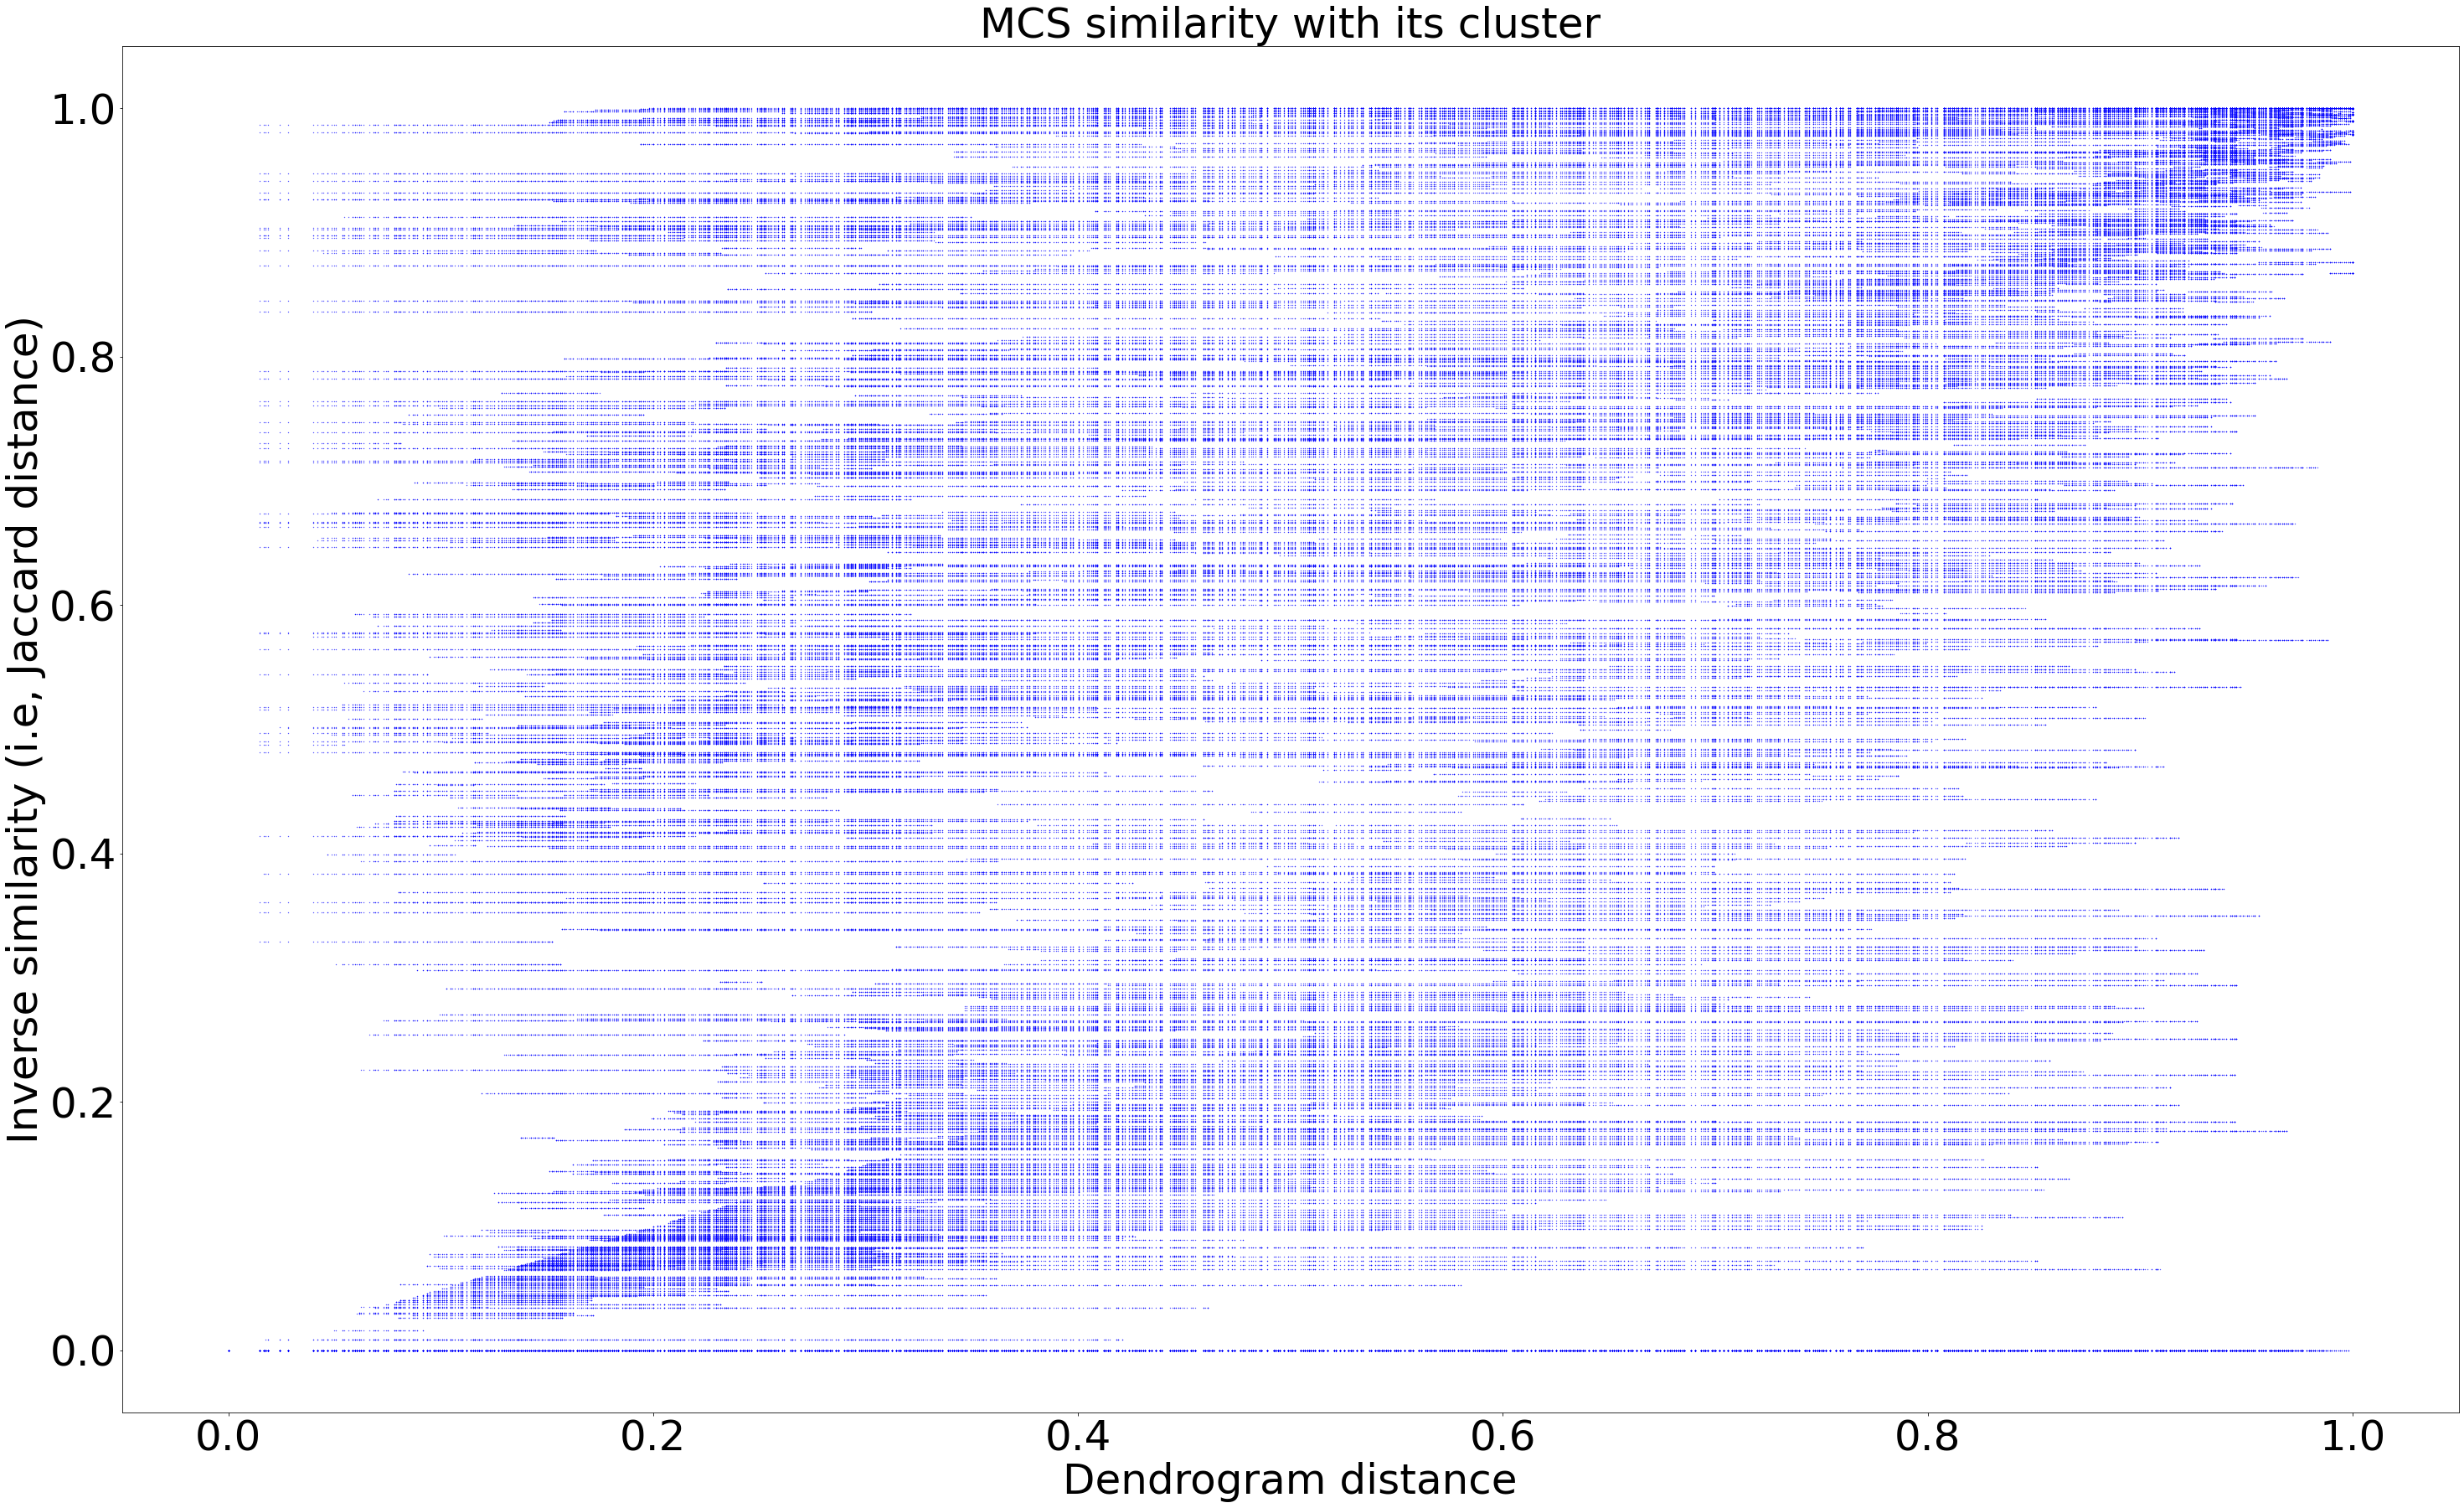

In [88]:
fig, ax = plt.subplots(figsize=(50,30))
#a.fill_between(x, y + 0.5, y - 0.5, alpha=0.5, color='b')

for i, distance in enumerate(dendrogram_distances):

    ax.scatter(distance*np.ones((len(similarities_mean_lst[i]),)), np.array(similarities_mean_lst[i]), color='blue', s=0.1)

fsize = 50
ax.set_title('MCS similarity with its cluster', fontsize=fsize)
ax.set_ylabel('Inverse similarity (i.e, Jaccard distance)', fontsize=fsize)
#ax.set_ylim([0.0, 1.0])
ax.tick_params(axis='x', labelsize=50)
ax.tick_params(axis='y', labelsize=50)
#ax.set_xscale('log')
#ax.set_yscale('log')
ax.set_xlabel('Dendrogram distance', fontsize=fsize)

Text(0.5, 0, 'Dendrogram distance')

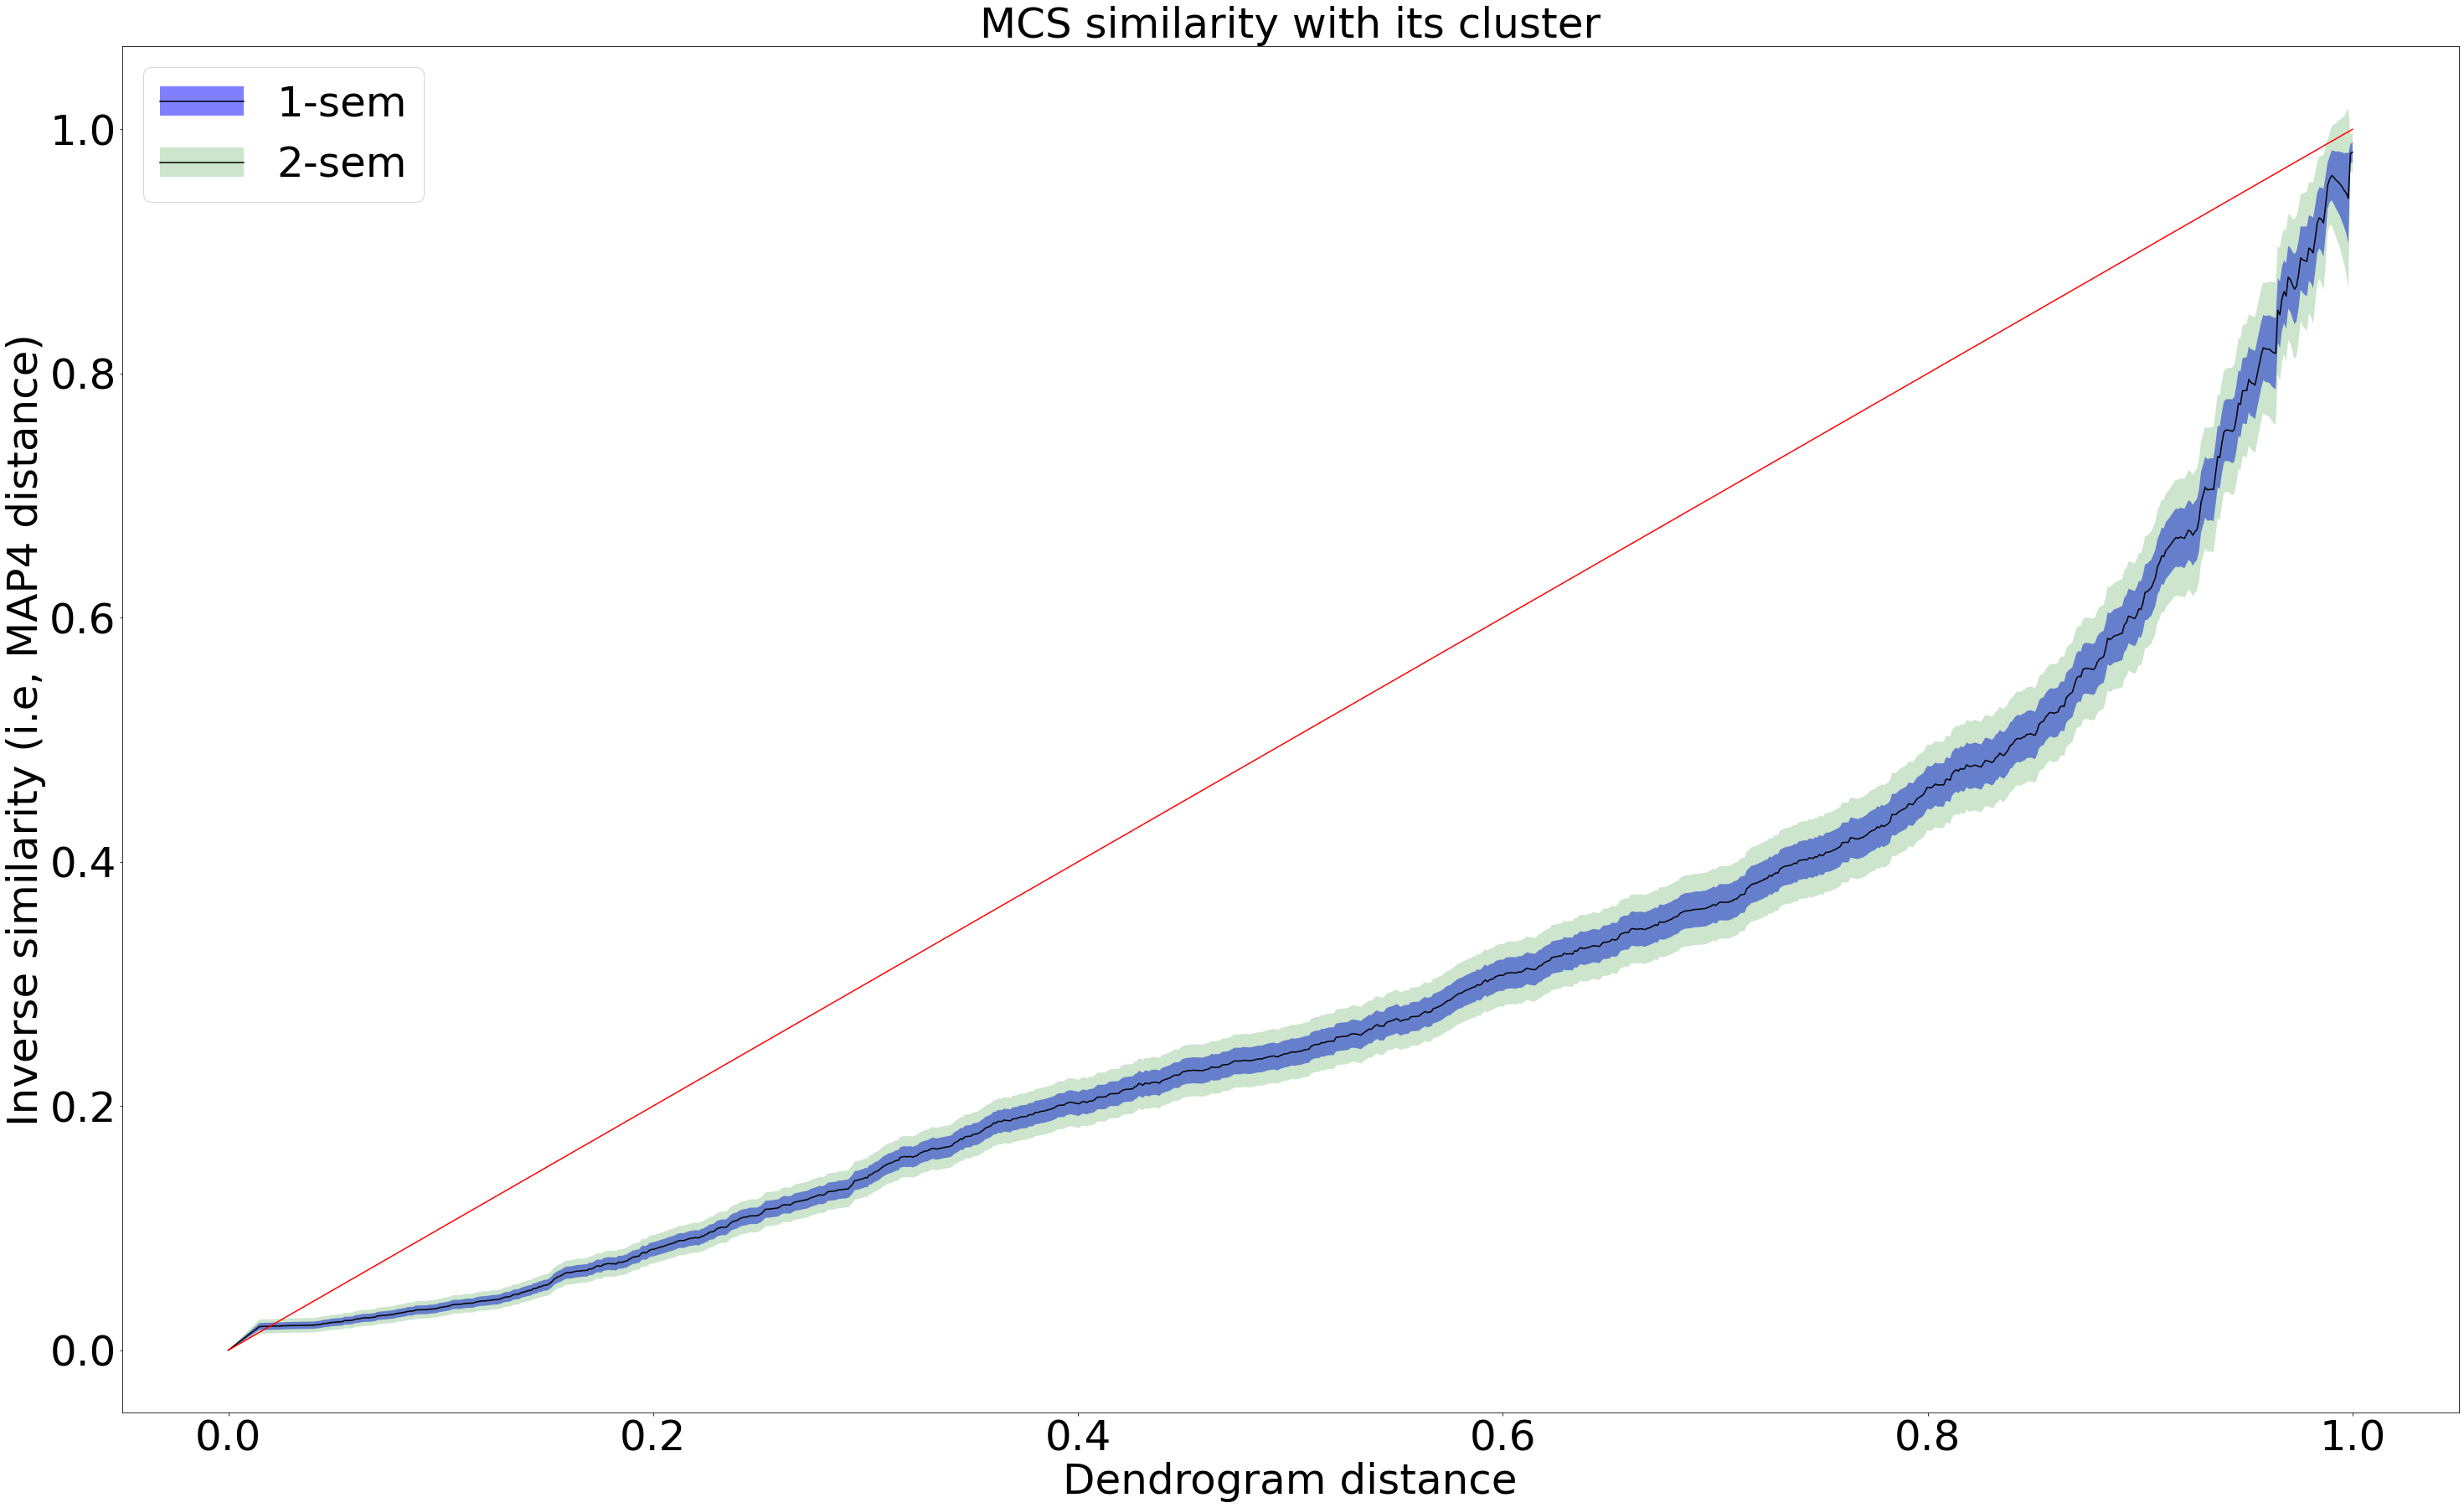

In [89]:
fig, ax = plt.subplots(figsize=(50,30))
#a.fill_between(x, y + 0.5, y - 0.5, alpha=0.5, color='b')

fsize = 50
p1 = ax.plot(dendrogram_distances, means_arr, color='black')
p2 = ax.fill(np.NaN, np.NaN, 'b', alpha=0.5)
p3 = ax.fill(np.NaN, np.NaN, 'g', alpha=0.2)
ax.fill_between(dendrogram_distances, means_arr-sem, means_arr+sem, alpha=.5, facecolor='blue')
ax.plot(np.linspace(0,1,10), np.linspace(0,1,10), color='red')
#ax.fill_between(dendrogram_distances, percentile_95, percentile_5, alpha=.5, facecolor='blue')
ax.fill_between(dendrogram_distances, means_arr-2*sem, means_arr+2*sem, alpha=.2, facecolor='g')
ax.legend([(p2[0], p1[0]), (p3[0], p1[0]), ], ['1-sem', '2-sem'], loc='upper left', prop={'size': 50})
ax.set_title('MCS similarity with its cluster', fontsize=fsize)
ax.set_ylabel('Inverse similarity (i.e, MAP4 distance)', fontsize=fsize)
#ax.set_ylim([0.0, 200.0])
#ax.set_xlim([0.0, 200.0])
ax.tick_params(axis='x', labelsize=50)
ax.tick_params(axis='y', labelsize=50)
ax.set_xlabel('Dendrogram distance', fontsize=fsize)

# 5. Optimum Distance Determination V2
Information obtained in previous section seems to not be enough to determine the optimum distance. This sections aims to find the distance at which the merge substructures start to be highly different.

It is necessary to differenciate between 3 cases: two leafs are merged (case 0), a leaf and a node are merged (case 1), or two nodes are merged (case 2).

In [90]:
dim = 1024
MAP4 = MAP4Calculator(dimensions=dim)
ENC = tm.Minhash(dim)

n_nodes = (df_smiles.shape[0] - 1)
len_cases = (df_smiles.shape[0] - 1)
MCS_merged_distances = []
cases = []
dendrogram_new_2 = []

for i, row in enumerate(children_new):
    print(i, end='\r')
    if row[0] <= n_nodes and row[1] <= n_nodes:
        cases.append(0)
        
        fps = MAP4.calculate_many([original_molecules[int(row[0])], original_molecules[int(row[1])]])
        MCS_merged_distances.append(ENC.get_distance(fps[0], fps[1]))
        
    elif (row[0] <= n_nodes and row[1] > n_nodes):
        cases.append(1)
        
        fps = MAP4.calculate_many([original_molecules[int(row[0])], substructures_molecules[int(row[1])-n_nodes-1]])
        MCS_merged_distances.append(ENC.get_distance(fps[0], fps[1]))
        
    elif (row[0] > n_nodes and row[1] <= n_nodes):
        cases.append(1)
        
        fps = MAP4.calculate_many([substructures_molecules[int(row[0])-n_nodes-1], original_molecules[int(row[1])]])
        MCS_merged_distances.append(ENC.get_distance(fps[0], fps[1]))
        
    else:
        cases.append(2)
        
        fps = MAP4.calculate_many([substructures_molecules[int(row[0])-n_nodes-1], substructures_molecules[int(row[1])-n_nodes-1]])
        MCS_merged_distances.append(ENC.get_distance(fps[0], fps[1]))
    
    dendrogram_new_2.append(dendrogram_distances[i])

cases = np.array(cases)
MCS_merged_distances = np.array(MCS_merged_distances)
dendrogram_new_2 = np.array(dendrogram_new_2)
    

NameError: name 'intercept' is not defined

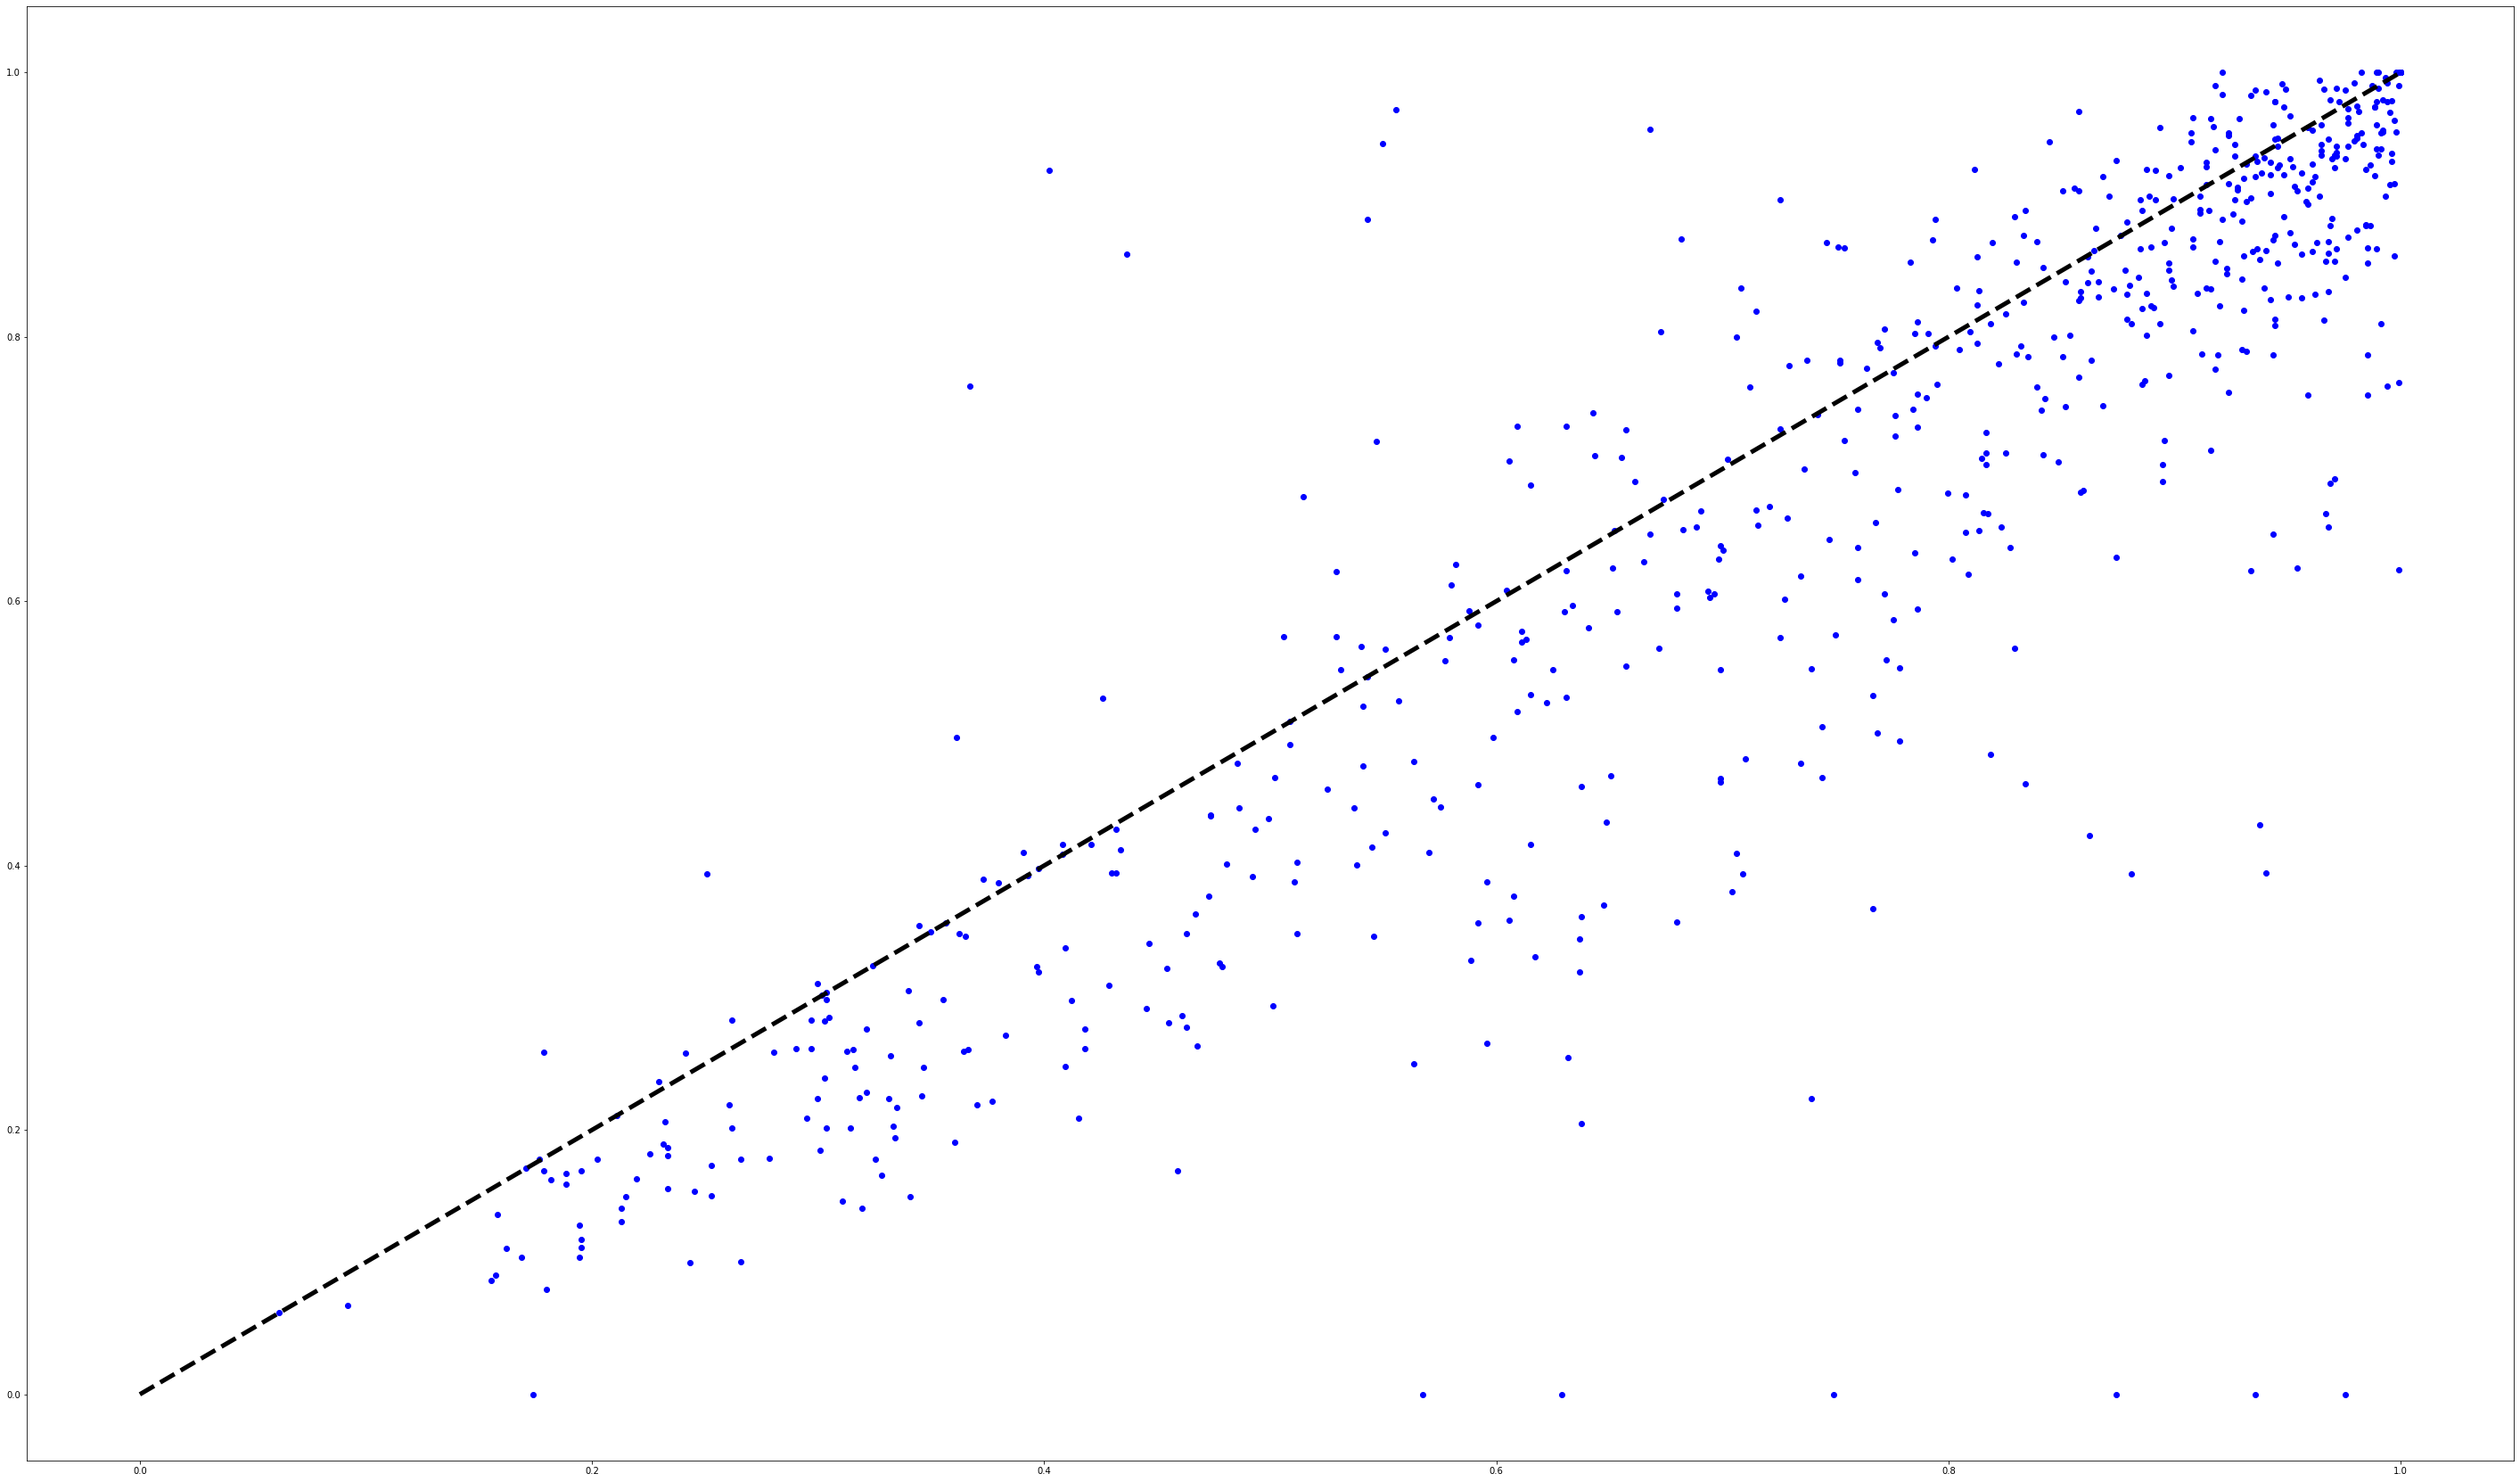

In [91]:
fig, ax = plt.subplots(figsize=(50,30))

dendrogram_new = np.array(dendrogram_new)

linspace = np.linspace(0, 1, 5)
#ax.scatter(dendrogram_new_2[cases == 0], MCS_merged_distances[cases == 0], color='red', label='Original Molecules Merging')
#ax.scatter(dendrogram_new_2[cases == 1], MCS_merged_distances[cases == 1], color='green', label='MCSs Merging')
ax.scatter(dendrogram_new_2[cases == 2], MCS_merged_distances[cases == 2], color='blue', label='MCSs Merging')
#ax.plot(dendrogram_new_2[cases == 2], intercept + slope*dendrogram_new_2[cases == 2], color='black', linestyle='--', linewidth=5)
ax.plot(linspace, linspace, color='black', linestyle='--', linewidth=5)
ax.plot(linspace, intercept + slope*linspace, color='red', linestyle='--', linewidth=5)


fsize = 50
ax.set_title('Merged MCS similarity analysis', fontsize=fsize)
ax.set_ylabel('Distance between MCSs', fontsize=fsize)
ax.tick_params(axis='x', labelsize=50)
ax.tick_params(axis='y', labelsize=50)
ax.legend(loc='upper left', prop={'size': 50})
#ax.set_xscale('log')
#ax.set_yscale('log')
ax.set_xlabel('Dendrogram distance', fontsize=fsize)

In [92]:
slope, intercept, r_value, p_value, std_err = scipy.stats.linregress(dendrogram_new_2[cases==2], MCS_merged_distances[cases == 2])

In [93]:
r_value

0.8820073549840628

# 6. Json for Platform

In [76]:
df_features = pd.read_csv('data/features.csv')
df_features.head()

,ID_unique,PubchemCID,ChromeAzurol,Other Metals,CMC [uM],EI24 index,SurfaceTension,Total_Antimicrobial,Total_Antitumoral,ALogP,...,rotatable_bond_count_PubChem,Topological Polar Surface Area,Total Number of Bonds,tpsa_PubChem,undefined_atom_stereo_count_PubChem,undefined_bond_stereo_count_PubChem,Wiener Path,Wiener Polarity,xlogp_PubChem,Zagreb Index
0,SF_293,19.0,NaN,NaN,NaN,NaN,NaN,24.0,13.0,-0.1582,...,1.0,77.76,11.0,77.8,0.0,0.0,146.0,15.0,1.2,52.0
1,SF_298,72.0,NaN,NaN,NaN,NaN,NaN,50.0,133.0,-0.1582,...,1.0,77.76,11.0,77.8,0.0,0.0,152.0,14.0,1.1,52.0
2,SF_446,338.0,NaN,NaN,NaN,NaN,NaN,55.0,22.0,0.4049,...,1.0,57.53,10.0,57.5,0.0,0.0,114.0,12.0,2.3,46.0
3,SF_197,692.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.3694,...,6.0,287.58,51.0,288.0,3.0,0.0,8736.0,84.0,2.3,246.0
4,BS_869,864.0,NaN,NaN,NaN,NaN,NaN,161.0,151.0,-0.2146,...,5.0,87.90,12.0,87.9,1.0,0.0,244.0,9.0,1.7,52.0


In [77]:
metadata_names = list(df_features.columns)[2:9]
metadata_names

['ChromeAzurol',
 'Other Metals',
 'CMC [uM]',
 'EI24 index',
 'SurfaceTension',
 'Total_Antimicrobial',
 'Total_Antitumoral']

In [78]:
features_names = list(df_features.columns)[9:]
features_names

['ALogP',
 'ALogP2',
 'Aromatic ring count',
 'atom_stereo_count_PubChem',
 'Atomic composition',
 'bond_stereo_count_PubChem',
 'complexity_PubChem',
 'covalent_unit_count_PubChem',
 'defined_atom_stereo_count_PubChem',
 'defined_bond_stereo_count_PubChem',
 'Exact Mass',
 'exact_mass_PubChem',
 'h_bond_acceptor_count_PubChem',
 'h_bond_donor_count_PubChem',
 'HBond Acceptors',
 'HBond Donors',
 'Heavy atom count',
 'heavy_atom_count_PubChem',
 'isotope_atom_count_PubChem',
 'Length over Breadth Max',
 'Length over Breadth Min',
 "Lipinski's Rule of Five Failures",
 'Molar refractivity',
 'molecular_weight_PubChem',
 'monoisotopic_mass_PubChem',
 'PubChem_ID',
 'Ring count',
 'Rotatable Bonds Count',
 'rotatable_bond_count_PubChem',
 'Topological Polar Surface Area',
 'Total Number of Bonds',
 'tpsa_PubChem',
 'undefined_atom_stereo_count_PubChem',
 'undefined_bond_stereo_count_PubChem',
 'Wiener Path',
 'Wiener Polarity',
 'xlogp_PubChem',
 'Zagreb Index']

In [79]:
df_metadata = df_features.drop(columns=features_names)
df_metadata = df_metadata.drop(columns= ['PubchemCID'])
df_metadata.head()

,ID_unique,ChromeAzurol,Other Metals,CMC [uM],EI24 index,SurfaceTension,Total_Antimicrobial,Total_Antitumoral
0,SF_293,NaN,NaN,NaN,NaN,NaN,24.0,13.0
1,SF_298,NaN,NaN,NaN,NaN,NaN,50.0,133.0
2,SF_446,NaN,NaN,NaN,NaN,NaN,55.0,22.0
3,SF_197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,BS_869,NaN,NaN,NaN,NaN,NaN,161.0,151.0


In [80]:
df_metadata = df_metadata.fillna(value="")
df_metadata = df_metadata.set_index('ID_unique')
df_metadata.head()

,ChromeAzurol,Other Metals,CMC [uM],EI24 index,SurfaceTension,Total_Antimicrobial,Total_Antitumoral
ID_unique,,,,,,,
SF_293,,,,,,24,13
SF_298,,,,,,50,133
SF_446,,,,,,55,22
SF_197,,,,,,,
BS_869,,,,,,161,151


In [81]:
df_features = df_features.drop(columns = metadata_names)
df_features = df_features.drop(columns = ['PubchemCID'])
df_features = df_features.set_index('ID_unique')
df_features.head()

,ALogP,ALogP2,Aromatic ring count,atom_stereo_count_PubChem,Atomic composition,bond_stereo_count_PubChem,complexity_PubChem,covalent_unit_count_PubChem,defined_atom_stereo_count_PubChem,defined_bond_stereo_count_PubChem,...,rotatable_bond_count_PubChem,Topological Polar Surface Area,Total Number of Bonds,tpsa_PubChem,undefined_atom_stereo_count_PubChem,undefined_bond_stereo_count_PubChem,Wiener Path,Wiener Polarity,xlogp_PubChem,Zagreb Index
ID_unique,,,,,,,,,,,,,,,,,,,,,
SF_293,-0.1582,0.025027,0.0,0.0,0.363636,0.0,157.0,1.0,0.0,0.0,...,1.0,77.76,11.0,77.8,0.0,0.0,146.0,15.0,1.2,52.0
SF_298,-0.1582,0.025027,0.0,0.0,0.363636,0.0,157.0,1.0,0.0,0.0,...,1.0,77.76,11.0,77.8,0.0,0.0,152.0,14.0,1.1,52.0
SF_446,0.4049,0.163944,0.0,0.0,0.300000,0.0,133.0,1.0,0.0,0.0,...,1.0,57.53,10.0,57.5,0.0,0.0,114.0,12.0,2.3,46.0
SF_197,-2.3694,5.614056,0.0,3.0,0.375000,0.0,1060.0,1.0,0.0,0.0,...,6.0,287.58,51.0,288.0,3.0,0.0,8736.0,84.0,2.3,246.0
BS_869,-0.2146,0.046053,0.0,1.0,0.333333,0.0,150.0,1.0,0.0,0.0,...,5.0,87.90,12.0,87.9,1.0,0.0,244.0,9.0,1.7,52.0


In [82]:
for row in df_features.iterrows():
    index = row[0]
    if row[1]['exact_mass_PubChem'] != 'null' and row[1]['monoisotopic_mass_PubChem'] != 'null':
        try:
            df_features.at[row[0], 'exact_mass_PubChem'] = int(row[1]['exact_mass_PubChem'].replace('.', ''))
            df_features.at[row[0], 'monoisotopic_mass_PubChem'] = int(row[1]['monoisotopic_mass_PubChem'].replace('.', ''))
        except:
            pass

In [83]:
df_features.loc['BS_869']['exact_mass_PubChem']

20604352203

In [84]:
df_features = df_features.fillna(value='null')

In [85]:
data_to_alex = {'leaf_':list(range(df_smiles.shape[0])), 'ID':list(df_smiles['ID'])}

In [86]:
df_to_alex = pd.DataFrame(data_to_alex)

In [87]:
df_to_alex.iloc[:100]['ID']

0     BS_0002
1     BS_0003
2     BS_0004
3     BS_0008
4     BS_0011
       ...   
95    BS_0144
96    BS_0145
97    BS_0146
98    BS_0147
99    BS_0148
Name: ID, Length: 100, dtype: object

In [89]:
# This is an old translator, now we are going to use the one provided by M.G. in the database


translator = {}

i=0
for row in df_to_alex.iterrows():
    string = row[1]['ID']
    lst = string.split('_')
    new_str = ''
    flag=False
    for char in lst[1]:
        
        if char != '0' or flag:
            new_str = new_str + char
            flag=True
            
    '''      
    if lst[0].startswith('E'):
        new_str = lst[0][1:]+'_'+new_str
    else:
        new_str = lst[0]+'_'+new_str
    '''
    new_str = lst[0]+'_'+new_str
    translator[string] = new_str
    #df_to_alex['ID']= df_to_alex['ID'].replace([string], new_str)
    i=i+1


In [91]:
df_map_bs = pd.read_csv('v2_files/BS_map_ids.csv')
df_map_bs = df_map_bs[['ID_unique_old', 'ID_unique']]
df_map_bs.head()

,ID_unique_old,ID_unique
0,BS_1,BS_0001
1,BS_2,BS_0002
2,BS_3,BS_0003
3,BS_4,BS_0004
4,BS_5,BS_0005


In [93]:
df_map_sf = pd.read_csv('v2_files/SF_map_ids.csv')
df_map_sf = df_map_sf[['ID_unique_old', 'ID_unique']]
df_map_sf.head()

,ID_unique_old,ID_unique
0,SF_1,SF_0001
1,SF_2,SF_0002
2,SF_3,SF_0003
3,SF_4,SF_0004
4,SF_5,SF_0005


In [94]:
df_map = pd.concat([df_map_sf, df_map_bs])
print(df_map.shape)
df_map.head()

(2265, 2)


,ID_unique_old,ID_unique
0,SF_1,SF_0001
1,SF_2,SF_0002
2,SF_3,SF_0003
3,SF_4,SF_0004
4,SF_5,SF_0005


In [98]:
translator = dict(zip(df_map['ID_unique'].values, df_map['ID_unique_old'].values))
translator

{'SF_0001': 'SF_1',
 'SF_0002': 'SF_2',
 'SF_0003': 'SF_3',
 'SF_0004': 'SF_4',
 'SF_0005': 'SF_5',
 'SF_0006': 'SF_6',
 'SF_0007': 'SF_7',
 'SF_0008': 'SF_8',
 'SF_0009': 'SF_9',
 'SF_0010': 'SF_10',
 'SF_0011': 'SF_11',
 'SF_0012': 'SF_12',
 'SF_0013': 'SF_13',
 'SF_0014': 'SF_14',
 'SF_0015': 'SF_15',
 'SF_0016': 'SF_16',
 'SF_0017': 'SF_17',
 'SF_0018': 'SF_18',
 'SF_0019': 'SF_19',
 'SF_0020': 'SF_20',
 'SF_0021': 'SF_21',
 'SF_0022': 'SF_22',
 'SF_0023': 'SF_23',
 'SF_0024': 'SF_24',
 'SF_0025': 'SF_25',
 'SF_0026': 'SF_26',
 'SF_0027': 'SF_27',
 'SF_0028': 'SF_28',
 'SF_0029': 'SF_29',
 'SF_0030': 'SF_30',
 'SF_0031': 'SF_31',
 'SF_0032': 'SF_32',
 'SF_0033': 'SF_33',
 'SF_0034': 'SF_34',
 'SF_0035': 'SF_35',
 'SF_0036': 'SF_36',
 'SF_0037': 'SF_37',
 'SF_0038': 'SF_38',
 'SF_0039': 'SF_39',
 'SF_0040': 'SF_40',
 'SF_0041': 'SF_41',
 'SF_0042': 'SF_42',
 'SF_0043': 'SF_43',
 'SF_0044': 'SF_44',
 'SF_0045': 'SF_45',
 'SF_0046': 'SF_46',
 'SF_0047': 'SF_47',
 'SF_0048': 'SF_48',
 

In [101]:
n_molecules = len(dendrogram_distances) + 1
nodes = {}
for i in range(n_molecules):
    leaf_key = 'leaf_' + str(i)
    nodes[leaf_key] = {}
    nodes[leaf_key]['count'] = 1
    nodes[leaf_key]['distance'] = 0
    unique_ID = df_to_alex.iloc[i]['ID']
    query_ID = translator[unique_ID]
    try:
        nodes[leaf_key]['features'] = list(df_features.loc[query_ID].values)
    except:
        print('Query on df_features failes. Tryed ID: ' + str(query_ID))
        nodes[leaf_key]['features'] = ['null' for x in range(len(features_names))]
    
    if unique_ID == unique_ID:
        nodes[leaf_key]['objects'] = [unique_ID]
    else:
        print('An index was detected to be NaN')
        nodes[leaf_key]['objects'] = [str(df_to_alex.iloc[i]['ID'])]
    try:
        parent = children_new[np.argwhere(children_new[:, 0] == i)[0][0], 2]
    except:
        parent = children_new[np.argwhere(children_new[:, 1] == i)[0][0], 2]
        
    nodes[leaf_key]['parent'] = 'node_' + str(int(parent-n_molecules))

Query on df_features failes. Tryed ID: EBS_01
Query on df_features failes. Tryed ID: EBS_02
Query on df_features failes. Tryed ID: EBS_03
Query on df_features failes. Tryed ID: EBS_04
Query on df_features failes. Tryed ID: EBS_05
Query on df_features failes. Tryed ID: EBS_06
Query on df_features failes. Tryed ID: EBS_08
Query on df_features failes. Tryed ID: EBS_09
Query on df_features failes. Tryed ID: EBS_10
Query on df_features failes. Tryed ID: EBS_11
Query on df_features failes. Tryed ID: EBS_12
Query on df_features failes. Tryed ID: EBS_13
Query on df_features failes. Tryed ID: EBS_14
Query on df_features failes. Tryed ID: EBS_15
Query on df_features failes. Tryed ID: EBS_16
Query on df_features failes. Tryed ID: EBS_17
Query on df_features failes. Tryed ID: EBS_18
Query on df_features failes. Tryed ID: EBS_19
Query on df_features failes. Tryed ID: SF_573
Query on df_features failes. Tryed ID: SF_575
Query on df_features failes. Tryed ID: SF_576
Query on df_features failes. Tryed

In [102]:
for i in range(len(dendrogram_distances)):
    j = i + n_molecules
    
    node_key = 'node_' + str(i)
    nodes[node_key] = {}
    nodes[node_key]['count'] = len(leaves[int(j)])
    nodes[node_key]['distance'] = dendrogram_distances[i]

    left_child = children_new[np.argwhere(children_new[:, 2] == j)[0][0], 1]
    right_child = children_new[np.argwhere(children_new[:, 2] == j)[0][0], 0]

    if left_child < n_molecules:
        nodes[node_key]['left_child'] = 'leaf_' + str(int(left_child))
    else:
        nodes[node_key]['left_child'] = 'node_' + str(int(left_child-n_molecules))

    if right_child < n_molecules:
        nodes[node_key]['right_child'] = 'leaf_' + str(int(right_child))
    else:
        nodes[node_key]['right_child'] = 'node_' + str(int(right_child - n_molecules))
      
    if j<(2*n_molecules -2):
        try:
            parent = children_new[np.argwhere(children_new[:, 0] == j)[0][0], 2]
        except:
            parent = children_new[np.argwhere(children_new[:, 1] == j)[0][0], 2]
        
        nodes[node_key]['parent'] = 'node_' + str(int(parent-n_molecules))

In [103]:
nodes['node_700']['count']

4

In [104]:
data = {'nodes':nodes, 'feature_names':features_names} #The final data for the json

In [105]:
metadata = {}
meta_nodes = {}
for i in range(n_molecules):
    leaf_key = 'leaf_' + str(i)
    meta_nodes[leaf_key] = []
    unique_ID = df_to_alex.iloc[i]['ID']
    query_ID = translator[unique_ID]
    #unique_ID = df_translator[df_translator['Current'] == str(df_to_alex.iloc[i]['ID'])]['Old'].values[0]
    try:
        meta_nodes[leaf_key] = list(df_metadata.loc[query_ID].values)
    except:
        print('Query on df_metadata failed. Tryed ID: ' + str(query_ID))
        meta_nodes[leaf_key] = ["" for x in range(len(metadata_names))]
    
    
metadata = {'nodes':meta_nodes, 'feature_names':metadata_names}

Query on df_metadata failed. Tryed ID: EBS_01
Query on df_metadata failed. Tryed ID: EBS_02
Query on df_metadata failed. Tryed ID: EBS_03
Query on df_metadata failed. Tryed ID: EBS_04
Query on df_metadata failed. Tryed ID: EBS_05
Query on df_metadata failed. Tryed ID: EBS_06
Query on df_metadata failed. Tryed ID: EBS_08
Query on df_metadata failed. Tryed ID: EBS_09
Query on df_metadata failed. Tryed ID: EBS_10
Query on df_metadata failed. Tryed ID: EBS_11
Query on df_metadata failed. Tryed ID: EBS_12
Query on df_metadata failed. Tryed ID: EBS_13
Query on df_metadata failed. Tryed ID: EBS_14
Query on df_metadata failed. Tryed ID: EBS_15
Query on df_metadata failed. Tryed ID: EBS_16
Query on df_metadata failed. Tryed ID: EBS_17
Query on df_metadata failed. Tryed ID: EBS_18
Query on df_metadata failed. Tryed ID: EBS_19
Query on df_metadata failed. Tryed ID: SF_573
Query on df_metadata failed. Tryed ID: SF_575
Query on df_metadata failed. Tryed ID: SF_576
Query on df_metadata failed. Tryed

In [106]:
metadata['nodes']

{'leaf_0': ['', '', '', '', '', 11.0, ''],
 'leaf_1': ['', '', '', '', '', 1.0, ''],
 'leaf_2': ['', '', '', '', '', 1.0, ''],
 'leaf_3': ['', '', '', '', '', '', 1.0],
 'leaf_4': ['', '', '', '', '', '', ''],
 'leaf_5': ['', '', '', '', '', '', ''],
 'leaf_6': ['', '', '', '', '', '', 1.0],
 'leaf_7': ['', '', 2.7, '', '', '', ''],
 'leaf_8': ['', '', 3000.0, '', '', '', ''],
 'leaf_9': ['', '', '', '', '', '', ''],
 'leaf_10': ['', '', '', '', '', '', ''],
 'leaf_11': ['', '', '', '', '', 1.0, ''],
 'leaf_12': ['', '', '', '', '', '', ''],
 'leaf_13': ['', '', '', '', '', 53.0, ''],
 'leaf_14': ['', '', '', '', '', '', ''],
 'leaf_15': ['', '', '', '', '', '', ''],
 'leaf_16': ['', '', '', '', '', '', ''],
 'leaf_17': ['', '', '', '', '', '', ''],
 'leaf_18': ['', '', '', '', '', '', ''],
 'leaf_19': ['', '', '', '', '', '', ''],
 'leaf_20': ['', '', '', '', '', '', ''],
 'leaf_21': ['', '', '', '', '', '', ''],
 'leaf_22': ['', '', '', '', '', '', ''],
 'leaf_23': ['', '', '', '', '

In [107]:
definitive_json = {'data':data, 'metadata':metadata}

In [108]:
with open('v2_files/heatmap_dendrogram.json', 'w') as outfile:
    json.dump(definitive_json, outfile)

# 7. Images for Platform

In [122]:
for k, mol in enumerate(original_molecules):
    Chem.Draw.MolToFile(mol, 'v2_files/leaf_/'+str(k)+'.png')
    print(Chem.MolToMolBlock(mol), file=open('v2_files/leaf_mol_/'+ str(k)+'.mol','w+'))

In [123]:
for k, mol in enumerate(substructures_molecules):
    Chem.Draw.MolToFile(mol, 'v2_files/node_/'+str(k)+'.png')
    print(Chem.MolToMolBlock(mol), file=open('v2_files/node_mol_/'+ str(k)+'.mol','w+'))

# 8. Output for Metabolic Disassembler

In [111]:
dendrogram_distances[1151]

0.5712890625

In [124]:
1- dendrogram_distances[1151]

0.4287109375

In [112]:
brothers_op = brothers[1151+len(brothers)+1]
for brother in brothers_op:
    print(leaves[brother])

[1861, 1860, 1862]
[922, 924]
[872, 1027, 867, 1029]
[1324, 1907, 1520, 1736]
[135, 293, 136, 301]
[107, 106, 1084, 105, 1086, 99, 868, 102, 103, 97, 100]
[358, 114, 462]
[1652, 1662, 1837]
[352, 399]
[1784, 1782, 1783]
[829, 830]
[1450, 1526, 1514, 1438, 1517, 1669, 1675]
[576, 577]
[1110, 1198, 1109, 1197, 1195, 1159, 1196, 1106, 1107, 1192, 1193, 1108, 1194]
[1421, 1651, 1598, 1805]
[914, 915, 916]
[1443, 1614, 1737]
[1795, 1796, 1791, 1801, 1806, 1794, 1802]
[599, 601, 600, 604, 602, 603]
[1330, 1634, 1475, 1923]
[1328, 1442, 1563]
[1928, 1929, 1930]
[1610, 1612, 1611, 1915, 1916, 1913, 1914]
[1024, 1030, 1028, 1031]
[201, 422]
[257, 440]
[1671, 1672, 1522, 1668, 1676, 1678]
[1714, 1715, 1713, 1716, 1717, 1664, 1686, 1684, 1685]
[861, 863, 866, 858, 865]
[1247, 1248]
[1171, 1172, 1173, 1174, 1175]
[1412, 1769]
[796, 826, 827]
[1704, 1705, 1703, 1706]
[1139, 1185, 1188, 1138, 1184, 1111, 1163, 831, 1112, 1113, 1114]
[1057, 1052, 1055, 1054, 1058, 1053, 1056]
[1155, 1156, 1153, 1154]

KeyError: 1435

In [113]:
with open('v2_files/to_metadisassembler/brothers_op.pkl', 'wb') as f:
    pickle.dump(brothers_op, f)

In [114]:
len(brothers)

1959

In [115]:
n_samples = len(brothers)+1
substructures_meta = []
isolated_molecules = []
for brother in brothers_op:
    if brother >= n_samples:
        substructures_meta.append(substructures_molecules[brother-n_samples])
    else:
        isolated_molecules.append(brother)
    

In [116]:
with open('v2_files/to_metadisassembler/substructures_meta.pkl', 'wb') as f:
    pickle.dump(substructures_meta, f)

In [117]:
with open('v2_files/to_metadisassembler/isolated_molecules.pkl', 'wb') as f:
    pickle.dump(isolated_molecules, f)

In [118]:
len(isolated_molecules)

385

In [120]:
len(substructures_meta)

424

In [121]:
len(brothers_op)

809

In [128]:
import sklearn
X_transformed = sklearn.manifold.MDS(n_components=2, metric='precomputed').fit_transform(distance_matrix)

<IPython.core.display.Javascript object>


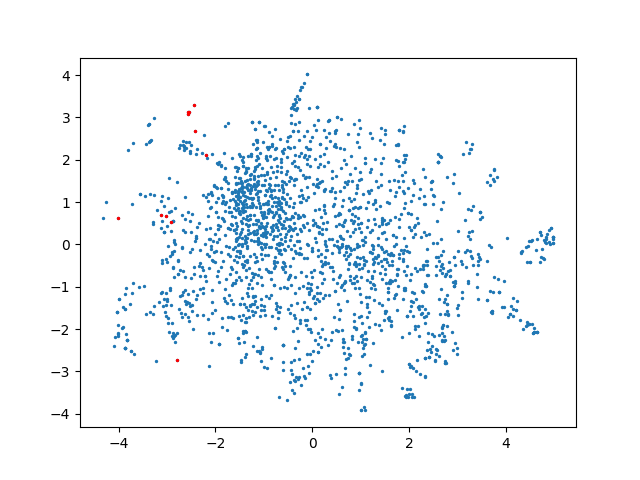

In [170]:
%matplotlib notebook
cluster = 5
plt.scatter(X_transformed[:, 0], X_transformed[:, 1], s=2)
plt.scatter(X_transformed[leaves[brothers_op[cluster]], 0], X_transformed[leaves[brothers_op[cluster]], 1], s=2, color='red')

In [136]:
brothers_op[0]

3110

In [165]:
leaves[brothers_op[179]]

[1117, 1166, 1115, 1116, 1165, 1141, 1187, 1191, 1140, 1190, 1186, 1189]

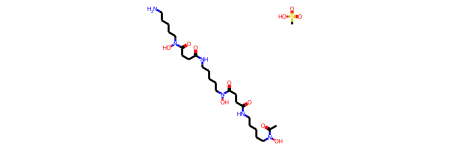

In [151]:
original_molecules[1814]

In [162]:
lengths = []
for brother in brothers_op:
    try:
        lengths.append(len(leaves[brother]))
    except:
        pass

In [164]:
np.argmax(lengths)

179